# Inverse FX Chain Predictor — **Effect presence + ORDER** (two-head Log-Mel Transformer)

From **dry + wet audio only**, predict which effects (EQ, Compressor, Reverb) were applied **and in which order**.

```
dry ─> Log-Mel ─┐
                ├─> fusion: dry ‖ wet ‖ (wet − dry) ─> Transformer ─> [CLS] ─┬─> presence head: P(EQ), P(Comp), P(Rev)
wet ─> Log-Mel ─┘                                                            └─> order head:    P(EQ before Comp), P(Rev before Comp)
```

**Why two order questions are enough.** EQ and Reverb are linear, so EQ→Reverb and Reverb→EQ give the *same audio*
(Section 12 verifies this on your data). The only audible order is **where the Compressor sits**. Presence × the two
order bits = the **12 audibly distinct chains**. The model outputs the most probable of those 12 (joint decoding).
The dataset's 15 chains map onto them; a perfect model can reach at most 80 % on the 15-chain view.

**Dataset:** [`APINAJA/inverse-fx-phase1-effect-order`](https://huggingface.co/datasets/APINAJA/inverse-fx-phase1-effect-order)
— 4,695 / 1,035 / 990 pairs (train / validation / test), 15 chains per dry clip, same parameters across the orders of a clip,
song-level splits. **Model repo:** `APINAJA/inverse-fx-order-logmel-transformer`.

### Kaggle settings
1. Accelerator **GPU T4 x2** · 2. Internet **ON** · 3. Add-ons → Secrets: **`HF_TOKEN`** (write) and **`WANDB_API_KEY`** (optional).

### Run
*Save Version → Save & Run All* (background, browser-safe) or *Run All*. After a Kaggle interruption: *Run All* again —
training resumes from the newest checkpoint (local or Hub), and W&B continues the same run.

## 1. Environment Setup

In [4]:
import os, sys, json, time, shutil, platform, subprocess, importlib

IS_KAGGLE = os.path.exists("/kaggle/working")
WORK_DIR = "/kaggle/working" if IS_KAGGLE else os.path.abspath("./order_work")
PKG_DIR = os.path.join(WORK_DIR, "fxp2")           # package written by the %%writefile cells
os.makedirs(PKG_DIR, exist_ok=True)
os.chdir(WORK_DIR)
if WORK_DIR not in sys.path:
    sys.path.insert(0, WORK_DIR)

os.environ.setdefault("OMP_NUM_THREADS", "2")       # 4 vCPUs shared by 2 DDP ranks + workers
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["PYTHONUNBUFFERED"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"    # no progress bars in the notebook or the torchrun workers
os.environ["HF_DATASETS_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TQDM_DISABLE"] = "1"
os.environ["WANDB_SILENT"] = "true"
os.environ["WANDB_CONSOLE"] = "off"

print(f"Kaggle: {IS_KAGGLE} | Python {platform.python_version()} | WORK_DIR={WORK_DIR}")
print(f"CPUs: {os.cpu_count()} | disk free in {WORK_DIR}: {shutil.disk_usage(WORK_DIR).free / 1e9:.1f} GB")
_hf_home = os.environ.get("HF_HOME", os.path.expanduser("~/.cache/huggingface"))
os.makedirs(_hf_home, exist_ok=True)
_free = shutil.disk_usage(_hf_home).free / 1e9
print(f"HF cache {_hf_home}: {_free:.1f} GB free (dataset needs ~30 GB: 13.7 GB download + Arrow cache)")
if _free < 32:
    print("WARNING: possibly not enough disk for the dataset cache.")

Kaggle: True | Python 3.13.15 | WORK_DIR=/kaggle/working
CPUs: 4 | disk free in /kaggle/working: 20.9 GB
HF cache /root/.cache/huggingface: 1148.8 GB free (dataset needs ~30 GB: 13.7 GB download + Arrow cache)


## 2. Install Dependencies
Only missing packages are installed; Kaggle's PyTorch/CUDA build is never touched.

In [5]:
REQUIRED = {"datasets": "datasets>=2.19", "huggingface_hub": "huggingface_hub>=0.23", "soundfile": "soundfile>=0.12",
            "librosa": "librosa>=0.10", "tensorboard": "tensorboard", "pandas": "pandas", "matplotlib": "matplotlib",
            "wandb": "wandb>=0.16"}
missing = [spec for mod, spec in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All dependencies already installed.")

All dependencies already installed.


## 3. Imports

In [6]:
%matplotlib inline
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import datasets, huggingface_hub, librosa, soundfile
datasets.disable_progress_bars()
huggingface_hub.utils.disable_progress_bars()
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
print(f"torch {torch.__version__} | datasets {datasets.__version__} | huggingface_hub {huggingface_hub.__version__} | "
      f"librosa {librosa.__version__}")

torch 2.11.0+cu128 | datasets 4.8.5 | huggingface_hub 1.29.0 | librosa 0.11.0


## 4. Configuration
All experiment settings live here; they are written to `experiment_config.json` (read by the `torchrun` processes) and
stored in every checkpoint.

| setting | value | why |
|---|---|---|
| batch | 16 per GPU → 32 | 4,695 pairs → 147 steps / epoch |
| epochs | 30, **no early stopping** | ≈ 4,400 steps; the cosine schedule runs to its low-LR end (Phase 1 stopped too early) |
| best checkpoint | validation **12-chain accuracy** | the main task; the test set is never used for selection |
| fusion | `concat_diff` (dry ‖ wet ‖ wet−dry) | makes static EQ changes explicit — Phase 1's EQ weakness |
| loss | BCE(presence) + 1.0 × masked BCE(order) | order loss only where both effects of a question are present |
| checkpoints | every 5 epochs + last; `best/` pushed with them | ≈ 6 pushes |
| printing | 1 progress line / 100 steps + 1 line / epoch | ≈ 75 lines for the whole run |

Expected time on 2×T4: ~20–40 s per epoch → 10–20 min, plus a one-off ~10–15 min to download/prepare 13.7 GB.
`NUM_EPOCHS` can be raised later; training then continues from the latest checkpoint.

In [7]:
CFG = dict(
    SEED=42, DETERMINISTIC=False,
    TASK="effect_order_two_head",

    # --- data (inputs = dry + wet audio ONLY) -------------------------------------------------
    HF_DATASET_ID="APINAJA/inverse-fx-phase1-effect-order",
    HF_DATASET_REVISION="a5d0eeff7f8d9062b30f1971a2bed342e0de2521",   # pinned commit (2026-10-16)
    HF_DATASET_LOCAL_PATH=None, HF_DATASETS_CACHE=None,
    DRY_AUDIO_COLUMN="dry_audio", WET_AUDIO_COLUMN="wet_audio",
    LABEL_COLUMNS=["eq_label", "compressor_label", "reverb_label"],               # presence targets
    POSITION_COLUMNS=["eq_position", "compressor_position", "reverb_position"],   # order targets (0 = absent)
    ID_COLUMN="sample_id",

    # --- audio + Log-Mel (same as Phase 1) ----------------------------------------------------------
    SAMPLE_RATE=44100, AUDIO_LENGTH_SECONDS=10.0, RESAMPLE_TYPE="soxr_hq",
    N_FFT=2048, HOP_LENGTH=512, WIN_LENGTH=None, N_MELS=128, F_MIN=20.0, F_MAX=20000.0, LOG_EPS=1e-6,
    NORM_MEAN=None, NORM_STD=None, NORM_STATS_NUM_EXAMPLES=128,

    # --- model ----------------------------------------------------------------------------------------
    FUSION="concat_diff",              # dry ‖ wet ‖ (wet − dry) -> [B, T, 384]
    D_MODEL=256, N_HEAD=4, NUM_LAYERS=4, DIM_FEEDFORWARD=512, DROPOUT=0.1,
    HEAD_HIDDEN_DIM=128, HEAD_DROPOUT=0.1,
    ORDER_LOSS_WEIGHT=1.0,

    # --- optimisation -------------------------------------------------------------------------------------
    BATCH_SIZE=16, EVAL_BATCH_SIZE=16,          # per GPU
    LEARNING_RATE=3e-4, NUM_EPOCHS=30, WEIGHT_DECAY=0.05, ADAM_BETAS=[0.9, 0.98], ADAM_EPS=1e-8,
    WARMUP_EPOCHS=2, MIN_LR_RATIO=0.02,
    USE_AMP=True, GRADIENT_CLIPPING=1.0,
    THRESHOLD=0.5,                               # presence threshold for the presence metrics
    BEST_METRIC="chain12_accuracy", BEST_METRIC_MODE="max", MIN_DELTA=0.0,
    EARLY_STOPPING_PATIENCE=None,
    LOG_EVERY_N_STEPS=10,                        # TensorBoard / W&B step scalars (no printing)
    PRINT_EVERY_N_STEPS=100,                     # one "step X/total" line every 100 steps

    # --- data loading / multi-GPU -------------------------------------------------------------------------
    NUM_WORKERS=2, PIN_MEMORY=True, PERSISTENT_WORKERS=True, PREFETCH_FACTOR=2,
    USE_DDP=True, DDP_TIMEOUT_MINUTES=60, FORCE_CPU=False,

    # --- checkpoints / resume -------------------------------------------------------------------------------
    CHECKPOINT_EVERY_N_EPOCHS=5,
    RESUME_FROM_CHECKPOINT="auto",               # "auto" | None | path | "checkpoint_epoch_XXX"
    WORK_DIR=WORK_DIR,
    CHECKPOINT_DIR=os.path.join(WORK_DIR, "checkpoints"),
    TENSORBOARD_DIR=os.path.join(WORK_DIR, "runs", "order_two_head"),
    RESULTS_DIR=os.path.join(WORK_DIR, "results"),

    # --- Hugging Face model repo ---------------------------------------------------------------------------------
    HF_MODEL_ID="APINAJA/inverse-fx-order-logmel-transformer",
    PUSH_TO_HUB=True, HF_PRIVATE_REPO=True, HF_UPLOAD_RETRIES=3,

    # --- Weights & Biases -------------------------------------------------------------------------------------------
    USE_WANDB=True,                              # needs the WANDB_API_KEY secret; silently off without it
    WANDB_PROJECT="inverse-fx-chain-predictor",
    WANDB_ENTITY=None,                           # None = your default W&B account
    WANDB_RUN_NAME="order-two-head-logmel-transformer",

    # --- checks -------------------------------------------------------------------------------------------------------
    RUN_SMOKE_TEST=True, SMOKE_TEST_DDP=True, SMOKE_TEST_HF_UPLOAD=True,
    ANALYSIS_MAX_GROUPS=None,                    # None = analyse every parameter set (Sections 12 and 26)
)
assert CFG["HF_MODEL_ID"] != CFG["HF_DATASET_ID"]
CONFIG_PATH = os.path.join(WORK_DIR, "experiment_config.json")

def save_config():
    with open(CONFIG_PATH, "w") as f:
        json.dump(CFG, f, indent=2)

for d in (CFG["CHECKPOINT_DIR"], CFG["TENSORBOARD_DIR"], CFG["RESULTS_DIR"], os.path.join(CFG["RESULTS_DIR"], "plots")):
    os.makedirs(d, exist_ok=True)
save_config()
print(f"Config written to {CONFIG_PATH} ({len(CFG)} keys)")

Config written to /kaggle/working/experiment_config.json (77 keys)


## 5. Hugging Face + Weights & Biases Authentication
Tokens come from Kaggle Secrets (`HF_TOKEN`, `WANDB_API_KEY`), are placed in the environment so the `torchrun` workers inherit them, and are **never printed or written to disk**.

In [8]:
def _secret(name):
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    except Exception:
        return os.environ.get(name)

_tok = _secret("HF_TOKEN")
HF_AUTH_OK = False
if _tok:
    os.environ["HF_TOKEN"] = _tok
    from huggingface_hub import HfApi
    try:
        print(f"Hugging Face: authenticated as '{HfApi(token=_tok).whoami().get('name')}'.")
        HF_AUTH_OK = True
    except Exception as e:
        print(f"WARNING: HF authentication failed ({type(e).__name__}). Checkpoints stay local only.")
else:
    print("WARNING: no HF_TOKEN secret — checkpoints stay local and cannot survive a session reset.")

_wb = _secret("WANDB_API_KEY") if CFG["USE_WANDB"] else None
WANDB_OK = False
if _wb:
    os.environ["WANDB_API_KEY"] = _wb
    try:
        import wandb
        _viewer = wandb.Api(api_key=_wb).viewer          # raises if the key is invalid
        _name = None
        for _a in ("username", "entity", "name"):
            try:
                _name = getattr(_viewer, _a)
                if _name:
                    break
            except Exception:
                pass
        print(f"W&B: authenticated as '{_name}' -> project '{CFG['WANDB_PROJECT']}'.")
        WANDB_OK = True
    except Exception as e:
        print(f"WARNING: W&B authentication failed ({type(e).__name__}); training continues with TensorBoard only.")
        os.environ.pop("WANDB_API_KEY", None)
else:
    print("W&B: off (no WANDB_API_KEY secret or USE_WANDB=False). TensorBoard is always on.")
del _tok, _wb

Hugging Face: authenticated as 'APINAJA'.
W&B: off (no WANDB_API_KEY secret or USE_WANDB=False). TensorBoard is always on.


## 6. GPU Detection
`NPROC` = number of `torchrun` training processes (one per GPU).

In [9]:
print("CUDA available:", torch.cuda.is_available())
NUM_GPUS = torch.cuda.device_count() if (torch.cuda.is_available() and not CFG["FORCE_CPU"]) else 0
print("GPU count:", NUM_GPUS)
for i in range(NUM_GPUS):
    p = torch.cuda.get_device_properties(i)
    print(f"  cuda:{i}  {p.name} | compute capability {p.major}.{p.minor} | {p.total_memory / 1e9:.1f} GB")
if not NUM_GPUS:
    print("WARNING: no GPU -> CPU fallback (very slow). On Kaggle select Accelerator = 'GPU T4 x2'.")
NPROC = NUM_GPUS if (CFG["USE_DDP"] and NUM_GPUS > 1) else 1
DEVICE = torch.device("cuda", 0) if NUM_GPUS else torch.device("cpu")
print(f"Training: {'DDP on %d GPUs' % NPROC if NPROC > 1 else ('single GPU' if NUM_GPUS else 'CPU')} | "
      f"effective batch {CFG['BATCH_SIZE'] * NPROC}")

import re
_PROGRESS_RE = re.compile(r"\d+%\||\|\s*[\d.]+\s*[kMG]?B\s*/|^(Processing Files|New Data Upload|Fetching|Downloading|Generating|Map|Filter)\b|^wandb:")

def run_torchrun(extra_args=(), nproc=None):
    """Launch train.py with torchrun. Shows only real log lines; full raw output -> logs/torchrun.log."""
    nproc = nproc or NPROC
    cmd = [sys.executable, "-m", "torch.distributed.run", "--standalone", f"--nproc_per_node={nproc}",
           os.path.join(WORK_DIR, "train.py"), "--config", CONFIG_PATH, *map(str, extra_args)]
    print("$", " ".join(cmd), flush=True)
    log_path = os.path.join(WORK_DIR, "logs", "torchrun.log")
    os.makedirs(os.path.dirname(log_path), exist_ok=True)
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1, env=os.environ.copy())
    lines = []
    try:
        with open(log_path, "a") as logf:
            for line in proc.stdout:
                logf.write(line)
                s = line.strip()
                if not s or _PROGRESS_RE.search(s):
                    continue
                print(line, end="", flush=True)
                lines.append(line)
        rc = proc.wait()
    except KeyboardInterrupt:
        proc.terminate(); proc.wait()
        raise
    if rc != 0:
        raise RuntimeError(f"torchrun exited with code {rc} (full log: {log_path})")
    return lines

CUDA available: True
GPU count: 2
  cuda:0  Tesla T4 | compute capability 7.5 | 15.6 GB
  cuda:1  Tesla T4 | compute capability 7.5 | 15.6 GB
Training: DDP on 2 GPUs | effective batch 32


## 7. Reproducibility + label definitions
Seeds Python / NumPy / PyTorch (each rank `SEED + rank`, re-seeded per epoch for resume reproducibility). Exact GPU
bit-reproducibility is still not guaranteed (cuDNN/cuBLAS algorithm choice, FP16 loss scaling, NCCL reductions).
`common.py` also defines the **15 dataset chains → 12 audible chains** mapping and the joint chain probability.

In [10]:
%%writefile {PKG_DIR}/__init__.py
"""Inverse FX Chain Predictor: effect presence + order (two-head Log-Mel Transformer)."""

Writing /kaggle/working/fxp2/__init__.py


In [11]:
%%writefile {PKG_DIR}/common.py
"""Shared constants and utilities: Inverse FX Chain Predictor — effect ORDER (two-head model).

Outputs of the model (5 logits):
    presence head  [EQ, Compressor, Reverb]                 3 sigmoids, BCE on every pair
    order head     [EQ before Compressor, Reverb before Compressor]
                                                            2 sigmoids, BCE only where both effects
                                                            of that question are present (masked)

Why only these two order questions: EQ (peaking biquad) and Reverb (Freeverb) are both
linear time-invariant, so they commute — EQ->Reverb and Reverb->EQ produce the same audio.
The only audible order information is where the (non-linear) Compressor sits relative to
EQ and to Reverb. Presence x those two bits gives exactly the 12 audibly distinct chains
(CHAINS12). The dataset's 15 chains (CHAINS15) map onto them many-to-one.
"""
from __future__ import annotations

import json
import os
import random
import sys
import tempfile
import time
from typing import Any, Dict, List, Tuple

import numpy as np
import torch

EFFECTS: List[str] = ["EQ", "Compressor", "Reverb"]

# 7 presence combinations (used for the presence confusion view).
COMBINATIONS: List[Tuple[str, Tuple[int, int, int]]] = [
    ("EQ", (1, 0, 0)),
    ("Compressor", (0, 1, 0)),
    ("Reverb", (0, 0, 1)),
    ("EQ + Compressor", (1, 1, 0)),
    ("EQ + Reverb", (1, 0, 1)),
    ("Compressor + Reverb", (0, 1, 1)),
    ("EQ + Compressor + Reverb", (1, 1, 1)),
]
COMBINATION_NAMES: List[str] = [name for name, _ in COMBINATIONS]
VECTOR_TO_COMBINATION: Dict[Tuple[int, int, int], int] = {
    vec: i for i, (_, vec) in enumerate(COMBINATIONS)
}

# --------------------------------------------------------------------------- order labels
ORDER_QUESTIONS: List[str] = ["EQ before Compressor", "Reverb before Compressor"]
ORDER_KEYS: List[str] = ["eq_before_comp", "rev_before_comp"]

# The dataset's 15 chains, in the dataset's own `chain_class` order (verified in the notebook).
CHAINS15: List[Tuple[str, ...]] = [
    ("EQ",), ("Compressor",), ("Reverb",),
    ("EQ", "Compressor"), ("Compressor", "EQ"), ("EQ", "Reverb"), ("Reverb", "EQ"),
    ("Compressor", "Reverb"), ("Reverb", "Compressor"),
    ("EQ", "Compressor", "Reverb"), ("EQ", "Reverb", "Compressor"), ("Compressor", "EQ", "Reverb"),
    ("Compressor", "Reverb", "EQ"), ("Reverb", "EQ", "Compressor"), ("Reverb", "Compressor", "EQ"),
]
CHAIN15_INDEX: Dict[Tuple[str, ...], int] = {c: i for i, c in enumerate(CHAINS15)}

# 12 audibly distinct chains: (long name, short name, presence, eq_before_comp, rev_before_comp,
#                             canonical 15-chain used when a single concrete order must be printed)
CHAINS12: List[Tuple[str, str, Tuple[int, int, int], Any, Any, Tuple[str, ...]]] = [
    ("EQ", "EQ", (1, 0, 0), None, None, ("EQ",)),
    ("Compressor", "Comp", (0, 1, 0), None, None, ("Compressor",)),
    ("Reverb", "Rev", (0, 0, 1), None, None, ("Reverb",)),
    ("EQ + Reverb (order not audible)", "{EQ,Rev}", (1, 0, 1), None, None, ("EQ", "Reverb")),
    ("EQ → Compressor", "EQ→Comp", (1, 1, 0), 1, None, ("EQ", "Compressor")),
    ("Compressor → EQ", "Comp→EQ", (1, 1, 0), 0, None, ("Compressor", "EQ")),
    ("Compressor → Reverb", "Comp→Rev", (0, 1, 1), None, 0, ("Compressor", "Reverb")),
    ("Reverb → Compressor", "Rev→Comp", (0, 1, 1), None, 1, ("Reverb", "Compressor")),
    ("Compressor → {EQ, Reverb}", "Comp→{EQ,Rev}", (1, 1, 1), 0, 0, ("Compressor", "EQ", "Reverb")),
    ("EQ → Compressor → Reverb", "EQ→Comp→Rev", (1, 1, 1), 1, 0, ("EQ", "Compressor", "Reverb")),
    ("Reverb → Compressor → EQ", "Rev→Comp→EQ", (1, 1, 1), 0, 1, ("Reverb", "Compressor", "EQ")),
    ("{EQ, Reverb} → Compressor", "{EQ,Rev}→Comp", (1, 1, 1), 1, 1, ("EQ", "Reverb", "Compressor")),
]
CHAIN12_NAMES: List[str] = [c[0] for c in CHAINS12]
CHAIN12_SHORT: List[str] = [c[1] for c in CHAINS12]
_C12_KEY = {(c[2], c[3], c[4]): i for i, c in enumerate(CHAINS12)}


def chain_from_positions(pos: Tuple[int, int, int]) -> Tuple[str, ...]:
    """(eq_position, compressor_position, reverb_position) -> ordered effect tuple."""
    present = [(int(p), e) for p, e in zip(pos, EFFECTS) if int(p) > 0]
    return tuple(e for _, e in sorted(present))


def targets_from_positions(pos: Tuple[int, int, int]) -> Dict[str, Any]:
    """All training/eval targets derived from the three position columns (0 = absent)."""
    pe, pc, pr = (int(x) for x in pos)
    presence = (int(pe > 0), int(pc > 0), int(pr > 0))
    o1 = int(pe < pc) if (pe > 0 and pc > 0) else None
    o2 = int(pr < pc) if (pr > 0 and pc > 0) else None
    chain = chain_from_positions(pos)
    return {
        "presence": presence,
        "order": (0 if o1 is None else o1, 0 if o2 is None else o2),
        "order_mask": (int(o1 is not None), int(o2 is not None)),
        "class12": _C12_KEY[(presence, o1, o2)],
        "chain15": CHAIN15_INDEX[chain],
        "chain": chain,
    }


def class12_of_chain15(idx15: int) -> int:
    chain = CHAINS15[idx15]
    pos = tuple((chain.index(e) + 1) if e in chain else 0 for e in EFFECTS)
    return targets_from_positions(pos)["class12"]


def chain12_probabilities(pres_probs, order_probs):
    """Joint probabilities of the 12 audible chains (numpy, [N,3] x [N,2] -> [N,12]).

    P(chain) = prod_k P(presence_k matches) * prod_j P(order bit j matches), using only the
    order bits that are defined for that chain. The 12 values sum to 1 - P(no effect).
    """
    p = np.asarray(pres_probs, dtype=np.float64)
    q = np.asarray(order_probs, dtype=np.float64)
    out = np.zeros((p.shape[0], len(CHAINS12)))
    for i, (_, _, presence, o1, o2, _) in enumerate(CHAINS12):
        v = np.ones(p.shape[0])
        for k in range(3):
            v *= p[:, k] if presence[k] else (1.0 - p[:, k])
        if o1 is not None:
            v *= q[:, 0] if o1 else (1.0 - q[:, 0])
        if o2 is not None:
            v *= q[:, 1] if o2 else (1.0 - q[:, 1])
        out[:, i] = v
    return out


# Columns the model is never allowed to see (research-integrity guard).
FORBIDDEN_INPUT_COLUMNS = (
    "effect_chain", "combination", "label", "eq_params", "compressor_params",
    "reverb_params", "parameters", "parameters_normalized", "effect_change_db",
    "low_effect_change", "dry_peak_dbfs", "wet_peak_dbfs", "presence_label", "slot_label",
    "chain_class", "num_effects", "parameter_set_id",
)


def log(msg: str, rank: int = 0, all_ranks: bool = False) -> None:
    """Rank-aware, timestamped print (flushes so torchrun output streams)."""
    if all_ranks or rank == 0:
        stamp = time.strftime("%H:%M:%S")
        prefix = f"[{stamp}]" + (f"[rank{rank}]" if all_ranks else "")
        print(f"{prefix} {msg}", flush=True)
        sys.stdout.flush()


def set_seed(seed: int, deterministic: bool = False) -> None:
    """Seed Python, NumPy and PyTorch (CPU + all CUDA devices).

    Exact bit-for-bit reproducibility is still NOT guaranteed on GPU: some
    CUDA kernels (atomics in reductions, cuBLAS/cuDNN algorithm choice, AMP
    loss-scaling dynamics, NCCL all-reduce ordering) are non-deterministic.
    `deterministic=True` asks PyTorch for deterministic kernels where they
    exist (warn-only), at some speed cost.
    """
    random.seed(seed)
    np.random.seed(seed % (2**32))
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    if deterministic:
        os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
        torch.backends.cudnn.deterministic = True
        torch.use_deterministic_algorithms(True, warn_only=True)


def get_rng_state() -> Dict[str, Any]:
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch_cpu": torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        state["torch_cuda_all"] = torch.cuda.get_rng_state_all()
    return state


def set_rng_state(state: Dict[str, Any]) -> None:
    try:
        random.setstate(state["python"])
        np.random.set_state(state["numpy"])
        torch.set_rng_state(state["torch_cpu"])
        if torch.cuda.is_available() and "torch_cuda_all" in state:
            cuda_states = state["torch_cuda_all"]
            if len(cuda_states) == torch.cuda.device_count():
                torch.cuda.set_rng_state_all(cuda_states)
    except Exception as exc:  # RNG restore is best-effort
        log(f"WARNING: could not fully restore RNG state ({exc}); continuing.")


def atomic_write_text(path: str, text: str) -> None:
    """Write text to `path` atomically (temp file + fsync + os.replace)."""
    directory = os.path.dirname(os.path.abspath(path))
    os.makedirs(directory, exist_ok=True)
    fd, tmp = tempfile.mkstemp(dir=directory, prefix=".tmp_", suffix=".part")
    try:
        with os.fdopen(fd, "w", encoding="utf-8") as fh:
            fh.write(text)
            fh.flush()
            os.fsync(fh.fileno())
        os.replace(tmp, path)
    finally:
        if os.path.exists(tmp):
            os.remove(tmp)


def atomic_write_json(path: str, obj: Any) -> None:
    atomic_write_text(path, json.dumps(obj, indent=2, sort_keys=False, default=_json_default))


def _json_default(o: Any) -> Any:
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, torch.Tensor):
        return o.detach().cpu().tolist()
    return str(o)


def read_json(path: str) -> Any:
    with open(path, "r", encoding="utf-8") as fh:
        return json.load(fh)


def load_config(path: str) -> Dict[str, Any]:
    cfg = read_json(path)
    cfg["_config_path"] = path
    return cfg


def expected_num_frames(cfg: Dict[str, Any]) -> int:
    """STFT frames for a fixed-length clip with center=True padding."""
    num_samples = int(round(cfg["SAMPLE_RATE"] * cfg["AUDIO_LENGTH_SECONDS"]))
    return 1 + num_samples // int(cfg["HOP_LENGTH"])


def fused_feature_dim(cfg: Dict[str, Any]) -> int:
    n_mels = int(cfg["N_MELS"])
    return {"concat": 2 * n_mels, "concat_diff": 3 * n_mels}[cfg["FUSION"]]


# Settings that define WHICH experiment a checkpoint belongs to. A checkpoint is only
# resumed if these match the current config (NUM_EPOCHS, LR, batch size, etc. may change).
FINGERPRINT_KEYS = (
    "HF_DATASET_ID", "HF_DATASET_REVISION", "DRY_AUDIO_COLUMN", "WET_AUDIO_COLUMN", "LABEL_COLUMNS",
    "SAMPLE_RATE", "AUDIO_LENGTH_SECONDS", "N_FFT", "HOP_LENGTH", "WIN_LENGTH", "N_MELS", "F_MIN", "F_MAX",
    "FUSION", "D_MODEL", "N_HEAD", "NUM_LAYERS", "DIM_FEEDFORWARD", "HEAD_HIDDEN_DIM", "TASK",
)


def run_fingerprint(cfg: Dict[str, Any]) -> Dict[str, Any]:
    return {k: cfg.get(k) for k in FINGERPRINT_KEYS}


def fingerprint_mismatch(saved_cfg: Dict[str, Any], cfg: Dict[str, Any]) -> Dict[str, Any]:
    """{key: (in checkpoint, now)} for every differing fingerprint key (empty = compatible)."""
    a, b = run_fingerprint(saved_cfg), run_fingerprint(cfg)
    return {k: (a[k], b[k]) for k in FINGERPRINT_KEYS if a[k] != b[k]}

Writing /kaggle/working/fxp2/common.py


In [12]:
from fxp2.common import (set_seed, EFFECTS, ORDER_QUESTIONS, ORDER_KEYS, CHAINS15, CHAINS12, CHAIN12_NAMES,
                         CHAIN12_SHORT, targets_from_positions, class12_of_chain15, read_json, atomic_write_json)
set_seed(CFG["SEED"], CFG["DETERMINISTIC"])
display(pd.DataFrame([{"dataset chain_class": i, "chain (15)": " → ".join(c),
                       "audible chain (12)": CHAIN12_NAMES[class12_of_chain15(i)]} for i, c in enumerate(CHAINS15)]
                     ).set_index("dataset chain_class"))

,chain (15),audible chain (12)
dataset chain_class,,
0,EQ,EQ
1,Compressor,Compressor
2,Reverb,Reverb
3,EQ → Compressor,EQ → Compressor
4,Compressor → EQ,Compressor → EQ
5,EQ → Reverb,EQ + Reverb (order not audible)
6,Reverb → EQ,EQ + Reverb (order not audible)
7,Compressor → Reverb,Compressor → Reverb
8,Reverb → Compressor,Reverb → Compressor


## 8. Load Dataset
Parquet shards (13.7 GB) are downloaded once and memory-mapped — audio is not loaded into RAM. Pinned revision.

In [13]:
from datasets import load_dataset, Audio
_kw = {k: v for k, v in (("revision", CFG["HF_DATASET_REVISION"]), ("cache_dir", CFG["HF_DATASETS_CACHE"])) if v}
t0 = time.time()
raw = load_dataset(CFG["HF_DATASET_LOCAL_PATH"] or CFG["HF_DATASET_ID"], **_kw)
print(f"{raw}\nloaded in {(time.time() - t0) / 60:.1f} min")
assert {"train", "validation", "test"} <= set(raw.keys())

DatasetDict({
    train: Dataset({
        features: ['sample_id', 'source_sample_id', 'source_id', 'source_category', 'source_song', 'split', 'dry_audio', 'wet_audio', 'effect_chain', 'combination', 'label', 'eq_label', 'compressor_label', 'reverb_label', 'presence_label', 'eq_position', 'compressor_position', 'reverb_position', 'slot_label', 'chain_class', 'num_effects', 'eq_params', 'compressor_params', 'reverb_params', 'parameters', 'parameters_normalized', 'effect_change_db', 'low_effect_change', 'sample_rate', 'num_channels', 'duration_s', 'dry_peak_dbfs', 'wet_peak_dbfs', 'dsp_backend', 'parameter_mode', 'random_seed', 'sample_seed', 'parameter_set_id'],
        num_rows: 4695
    })
    validation: Dataset({
        features: ['sample_id', 'source_sample_id', 'source_id', 'source_category', 'source_song', 'split', 'dry_audio', 'wet_audio', 'effect_chain', 'combination', 'label', 'eq_label', 'compressor_label', 'reverb_label', 'presence_label', 'eq_position', 'compressor_positio

## 9. Inspect Dataset
Label consistency (position columns vs presence / `chain_class`), chains per split, 15 pairs per dry clip, identical parameters inside each `parameter_set_id`, and no song overlap between splits.

In [14]:
meta_cols = ["sample_id", "source_sample_id", "source_song", "source_category", "chain_class", "parameter_set_id",
             "eq_params", "compressor_params", "reverb_params", *CFG["LABEL_COLUMNS"], *CFG["POSITION_COLUMNS"]]
frames = {s: raw[s].select_columns([c for c in meta_cols if c in raw[s].column_names]).to_pandas() for s in raw}
summary = []
for s, df in frames.items():
    tg = [targets_from_positions(tuple(p)) for p in df[CFG["POSITION_COLUMNS"]].to_numpy()]
    df["chain15"] = [t["chain15"] for t in tg]; df["class12"] = [t["class12"] for t in tg]
    pres = np.array([t["presence"] for t in tg])
    bad_pres = int((pres != df[CFG["LABEL_COLUMNS"]].to_numpy()).any(axis=1).sum())
    bad_chain = int((df["chain15"] != df["chain_class"]).sum()) if "chain_class" in df else -1
    per_clip = df.groupby("source_sample_id").size()
    param_bad = sum(int((df.groupby("parameter_set_id")[c].nunique(dropna=False) > 1).sum())
                    for c in ("eq_params", "compressor_params", "reverb_params") if c in df)
    summary.append({"split": s, "pairs": len(df), "dry clips": df["source_sample_id"].nunique(),
                    "songs": df["source_song"].nunique(), "pairs per dry clip": f"{per_clip.min()}–{per_clip.max()}",
                    "presence≠positions": bad_pres, "chain_class mismatches": bad_chain,
                    "param sets with differing params": param_bad})
display(pd.DataFrame(summary).set_index("split"))
assert all(r["presence≠positions"] == 0 and r["chain_class mismatches"] == 0 for r in summary), "label inconsistency!"
songs = {s: set(df["source_song"]) for s, df in frames.items()}
print("Song overlap train∩val:", len(songs["train"] & songs["validation"]), "| train∩test:", len(songs["train"] & songs["test"]),
      "| val∩test:", len(songs["validation"] & songs["test"]))
display(Markdown("**Pairs per audible chain (12 classes)**"))
display(pd.DataFrame({s: df["class12"].value_counts().reindex(range(12), fill_value=0).values for s, df in frames.items()},
                     index=CHAIN12_NAMES))
print("Model inputs: ONLY", CFG["DRY_AUDIO_COLUMN"], "+", CFG["WET_AUDIO_COLUMN"])

,pairs,dry clips,songs,pairs per dry clip,presence≠positions,chain_class mismatches,param sets with differing params
split,,,,,,,
train,4695,313,105,15–15,0,0,0
validation,1035,69,23,15–15,0,0,0
test,990,66,22,15–15,0,0,0


Song overlap train∩val: 0 | train∩test: 0 | val∩test: 0


**Pairs per audible chain (12 classes)**

,train,validation,test
EQ,313,69,66
Compressor,313,69,66
Reverb,313,69,66
EQ + Reverb (order not audible),626,138,132
EQ → Compressor,313,69,66
Compressor → EQ,313,69,66
Compressor → Reverb,313,69,66
Reverb → Compressor,313,69,66
"Compressor → {EQ, Reverb}",626,138,132
EQ → Compressor → Reverb,313,69,66


Model inputs: ONLY dry_audio + wet_audio


## 10. Audio Preprocessing
mono, 44.1 kHz, exactly 10 s (crop / zero-pad), float32, no normalisation — identical to Phase 1.

In [15]:
%%writefile {PKG_DIR}/audio.py
"""Deterministic audio preprocessing (same as Phase 1).

    decode (soundfile, from the raw bytes stored in the HF parquet)
      -> float32
      -> mono (mean over channels)
      -> resample to SAMPLE_RATE if needed (soxr_hq, deterministic)
      -> fixed length: crop from sample 0 / zero-pad at the end
      -> float32 numpy array of shape [SAMPLE_RATE * AUDIO_LENGTH_SECONDS]

No loudness normalisation, no peak normalisation and no clipping are applied:
level and dynamics differences between dry and wet audio are exactly the
evidence the model needs to detect a compressor (and EQ gain changes).
The source dataset is never modified; decoding happens on the fly.
"""
from __future__ import annotations

import io
from typing import Any, Dict, Tuple

import numpy as np
import soundfile as sf


def _decode_bytes_or_path(value: Dict[str, Any]) -> Tuple[np.ndarray, int]:
    data = value.get("bytes")
    path = value.get("path")
    if data is not None:
        audio, sr = sf.read(io.BytesIO(data), dtype="float32", always_2d=True)
    elif path:
        audio, sr = sf.read(path, dtype="float32", always_2d=True)
    else:
        raise ValueError("Audio value has neither 'bytes' nor 'path'.")
    return audio, int(sr)  # audio: [num_samples, channels]


def decode_audio_value(value: Any, default_sr: int) -> Tuple[np.ndarray, int]:
    """Return (mono float32 waveform [N], sample_rate) from any HF audio cell."""
    if isinstance(value, dict) and ("bytes" in value or "path" in value) and value.get("array") is None:
        audio, sr = _decode_bytes_or_path(value)
        mono = audio.mean(axis=1) if audio.shape[1] > 1 else audio[:, 0]
        return np.ascontiguousarray(mono, dtype=np.float32), sr
    if isinstance(value, dict) and "array" in value:  # already-decoded HF Audio
        arr = np.asarray(value["array"], dtype=np.float32)
        sr = int(value.get("sampling_rate") or default_sr)
    else:  # AudioDecoder (datasets>=4) or raw array
        if hasattr(value, "get_all_samples"):
            samples = value.get_all_samples()
            arr = samples.data.numpy().astype(np.float32)  # [C, N]
            sr = int(samples.sample_rate)
            arr = arr.mean(axis=0) if arr.ndim == 2 else arr
            return np.ascontiguousarray(arr, dtype=np.float32), sr
        arr = np.asarray(value, dtype=np.float32)
        sr = default_sr
    if arr.ndim == 2:  # [C, N] or [N, C] -> mono
        arr = arr.mean(axis=0) if arr.shape[0] < arr.shape[1] else arr.mean(axis=1)
    return np.ascontiguousarray(arr, dtype=np.float32), sr


def fix_length(wave: np.ndarray, num_samples: int) -> np.ndarray:
    """Deterministic crop (from the start) or zero-pad (at the end)."""
    n = wave.shape[0]
    if n >= num_samples:
        return wave[:num_samples]
    out = np.zeros(num_samples, dtype=np.float32)
    out[:n] = wave
    return out


class AudioPreprocessor:
    """Callable that maps one HF audio cell to a fixed-length float32 array."""

    def __init__(self, cfg: Dict[str, Any]):
        self.sample_rate = int(cfg["SAMPLE_RATE"])
        self.num_samples = int(round(self.sample_rate * float(cfg["AUDIO_LENGTH_SECONDS"])))
        self.resample_type = cfg.get("RESAMPLE_TYPE", "soxr_hq")

    def __call__(self, value: Any) -> np.ndarray:
        wave, sr = decode_audio_value(value, self.sample_rate)
        if sr != self.sample_rate:
            import librosa  # lazy: only needed if a file is not at 44.1 kHz

            wave = librosa.resample(wave, orig_sr=sr, target_sr=self.sample_rate,
                                    res_type=self.resample_type).astype(np.float32)
        wave = fix_length(wave, self.num_samples)
        if not np.all(np.isfinite(wave)):
            wave = np.nan_to_num(wave, nan=0.0, posinf=0.0, neginf=0.0)
        return wave.astype(np.float32, copy=False)

    def describe(self) -> Dict[str, Any]:
        return {"sample_rate": self.sample_rate, "num_samples": self.num_samples,
                "channels": "mono (mean of channels)", "dtype": "float32",
                "length_policy": "crop from start / zero-pad at end",
                "resample_type": self.resample_type, "normalisation": "none"}

Writing /kaggle/working/fxp2/audio.py


In [16]:
from fxp2.audio import AudioPreprocessor
pre = AudioPreprocessor(CFG)
_ex = raw["validation"].cast_column("dry_audio", Audio(decode=False)).cast_column("wet_audio", Audio(decode=False))[0]
dry0, wet0 = pre(_ex["dry_audio"]), pre(_ex["wet_audio"])
print(pre.describe()); print("dry", dry0.shape, dry0.dtype, "| wet", wet0.shape, wet0.dtype)

{'sample_rate': 44100, 'num_samples': 441000, 'channels': 'mono (mean of channels)', 'dtype': 'float32', 'length_policy': 'crop from start / zero-pad at end', 'resample_type': 'soxr_hq', 'normalisation': 'none'}
dry (441000,) float32 | wet (441000,) float32


## 11. Log-Mel Feature Extraction
Computed on the GPU inside the model (float32). Below: the same clip and parameters rendered as **Comp → Reverb** and **Reverb → Comp** — the order difference the model has to hear.

In [17]:
%%writefile {PKG_DIR}/features.py
"""Log-Mel feature extraction (identical configuration for dry and wet audio).

waveform [B, N]  --STFT(n_fft, hop, hann, center=True)-->  |X|^2  [B, n_fft//2+1, T]
                 --mel filterbank (Slaney, f_min..f_max)--> [B, n_mels, T]
                 --log(x + eps)--> --(x - NORM_MEAN) / NORM_STD--> [B, n_mels, T]

With the default config (44.1 kHz, 10 s, hop 512, n_mels 128):
    N = 441000 samples, T = 1 + 441000 // 512 = 862 frames  ->  [B, 128, 862]

NORM_MEAN / NORM_STD are two global scalars estimated once from training
audio (dry and wet pooled). A single shared affine keeps the absolute level
difference between dry and wet intact (no per-example / per-signal norm).
The extractor runs on the GPU inside the model, always in float32
(autocast disabled), so the STFT is numerically safe under FP16 AMP.
"""
from __future__ import annotations

from typing import Any, Dict

import numpy as np
import torch
import torch.nn as nn


def mel_filterbank(cfg: Dict[str, Any]) -> torch.Tensor:
    import librosa

    fb = librosa.filters.mel(
        sr=int(cfg["SAMPLE_RATE"]), n_fft=int(cfg["N_FFT"]), n_mels=int(cfg["N_MELS"]),
        fmin=float(cfg["F_MIN"]), fmax=float(cfg["F_MAX"]), htk=False, norm="slaney",
    )
    return torch.from_numpy(fb.astype(np.float32))  # [n_mels, n_fft//2 + 1]


class LogMelExtractor(nn.Module):
    def __init__(self, cfg: Dict[str, Any]):
        super().__init__()
        self.n_fft = int(cfg["N_FFT"])
        self.hop_length = int(cfg["HOP_LENGTH"])
        self.win_length = int(cfg.get("WIN_LENGTH") or self.n_fft)
        self.log_eps = float(cfg["LOG_EPS"])
        self.register_buffer("window", torch.hann_window(self.win_length, periodic=True), persistent=False)
        self.register_buffer("mel_fb", mel_filterbank(cfg), persistent=False)
        mean = cfg.get("NORM_MEAN")
        std = cfg.get("NORM_STD")
        # Persistent: normalisation stats travel inside every checkpoint.
        self.register_buffer("norm_mean", torch.tensor(float(0.0 if mean is None else mean)))
        self.register_buffer("norm_std", torch.tensor(float(1.0 if std is None else std)))

    def set_normalization(self, mean: float, std: float) -> None:
        self.norm_mean.fill_(float(mean))
        self.norm_std.fill_(float(max(std, 1e-6)))

    def raw_log_mel(self, wave: torch.Tensor) -> torch.Tensor:
        """[B, N] float waveform -> un-normalised log-mel [B, n_mels, T] (float32)."""
        with torch.autocast(device_type=wave.device.type, enabled=False):
            wave = wave.float()
            spec = torch.stft(wave, n_fft=self.n_fft, hop_length=self.hop_length,
                              win_length=self.win_length, window=self.window,
                              center=True, pad_mode="reflect", return_complex=True)
            power = spec.real.pow(2) + spec.imag.pow(2)          # [B, F, T]
            mel = torch.matmul(self.mel_fb, power)               # [B, n_mels, T]
            return torch.log(mel + self.log_eps)

    def forward(self, wave: torch.Tensor) -> torch.Tensor:
        log_mel = self.raw_log_mel(wave)
        return (log_mel - self.norm_mean) / self.norm_std


@torch.no_grad()
def compute_norm_stats(dataset, cfg: Dict[str, Any], device: torch.device) -> Dict[str, float]:
    """Global mean/std of log-mel over a deterministic subset of TRAIN audio.

    Uses the first NORM_STATS_NUM_EXAMPLES indices of a seeded permutation of
    the training split (dry and wet pooled). Never touches validation/test.
    """
    extractor = LogMelExtractor({**cfg, "NORM_MEAN": 0.0, "NORM_STD": 1.0}).to(device)
    n = min(int(cfg["NORM_STATS_NUM_EXAMPLES"]), len(dataset))
    order = np.random.RandomState(int(cfg["SEED"])).permutation(len(dataset))[:n]
    total, total_sq, count = 0.0, 0.0, 0
    for idx in order.tolist():
        item = dataset[idx]
        waves = torch.stack([item["dry"], item["wet"]]).to(device)
        lm = extractor.raw_log_mel(waves).double()
        total += lm.sum().item()
        total_sq += lm.pow(2).sum().item()
        count += lm.numel()
    mean = total / count
    std = float(np.sqrt(max(total_sq / count - mean**2, 1e-12)))
    return {"NORM_MEAN": float(mean), "NORM_STD": std, "NORM_STATS_INDICES": order.tolist()}

Writing /kaggle/working/fxp2/features.py


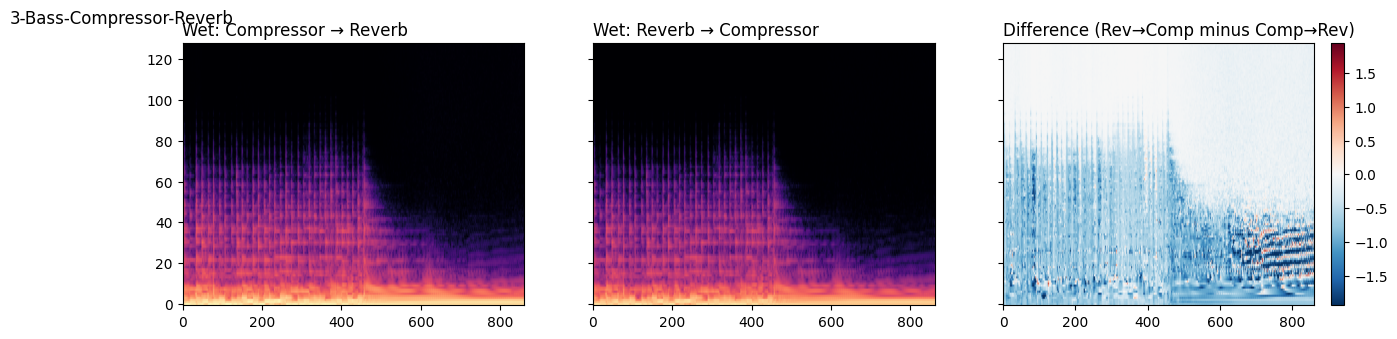

Log-Mel per signal: [B, n_mels, T] = (1, 128, 862)


In [18]:
from fxp2.features import LogMelExtractor
from fxp2.common import expected_num_frames
_lm = LogMelExtractor(CFG).to(DEVICE)
vf = frames["validation"]
_g = vf[vf["chain15"].isin([7, 8])].groupby("parameter_set_id").filter(lambda g: len(g) == 2)
if len(_g):
    gid = _g["parameter_set_id"].iloc[0]
    rows = _g[_g["parameter_set_id"] == gid].sort_values("chain15")
    vsplit = raw["validation"].cast_column("wet_audio", Audio(decode=False))
    waves = [pre(vsplit[int(i)]["wet_audio"]) for i in rows.index]
    with torch.no_grad():
        lm = _lm.raw_log_mel(torch.from_numpy(np.stack(waves)).to(DEVICE)).cpu().numpy()
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.4), dpi=100, sharey=True)
    lo, hi = np.percentile(lm, 5), lm.max()
    for ax, m, t in zip(axes[:2], lm, ["Wet: Compressor → Reverb", "Wet: Reverb → Compressor"]):
        ax.imshow(m, origin="lower", aspect="auto", cmap="magma", vmin=lo, vmax=hi); ax.set_title(t, loc="left")
    d = lm[1] - lm[0]; lim = float(np.percentile(np.abs(d), 99)) or 1.0
    im = axes[2].imshow(d, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[2].set_title("Difference (Rev→Comp minus Comp→Rev)", loc="left"); fig.colorbar(im, ax=axes[2], fraction=0.04)
    fig.suptitle(f"{gid}", x=0.01, ha="left"); plt.show()
print("Log-Mel per signal: [B, n_mels, T] =", (1, CFG["N_MELS"], expected_num_frames(CFG)))
del _lm

## 12. Data Checks: EQ↔Reverb identity and order audibility (validation split)
Rows with the same `parameter_set_id` are the same clip and parameters in every order, so the **swapped-order partner of each
pair is in the dataset**. Two measurements, `diff_db = 20·log10(rms(wet − wet_partner) / rms(wet))`:
* **Commute check**: EQ↔Reverb swaps should be ≈ identical (≪ −60 dB). This justifies merging 15 → 12 chains.
* **Order audibility**: for each order question, how different the swapped order sounds. Used later to break down test accuracy.

Metadata is used only for analysis — never as model input.

In [19]:
%%writefile {PKG_DIR}/analysis.py
"""Data checks that use the dataset's paired renders (same parameters, different order).

Rows with the same `parameter_set_id` are the same dry clip + same effect parameters, rendered
in every order of that effect set. So, for any row, the "swapped-order partner" is in the dataset:

* commute check: EQ<->Reverb swapped chains (EQ->Rev vs Rev->EQ, Comp->EQ->Rev vs Comp->Rev->EQ,
  EQ->Rev->Comp vs Rev->EQ->Comp) should be numerically identical if both effects are linear.
* order audibility: for each defined order question (EQ vs Comp, Reverb vs Comp) the partner is
  the same chain with EQ (or Reverb) moved to the other side of the Compressor. The level of the
  difference signal tells how audible that order decision is:
      diff_db = 20 log10( rms(wet - wet_partner) / rms(wet) )
Labels / metadata are used here for analysis only; they are never model inputs.
"""
from __future__ import annotations

from collections import defaultdict
from typing import Any, Dict, List, Optional, Tuple

import numpy as np

from .common import CHAIN15_INDEX, CHAINS15, EFFECTS, ORDER_KEYS, chain_from_positions

AUDIBILITY_BINS = [(-np.inf, -40.0, "< −40 dB\n(practically identical)"),
                   (-40.0, -20.0, "−40 … −20 dB\n(subtle)"),
                   (-20.0, np.inf, "> −20 dB\n(clear)")]


def _move_to_other_side(chain: Tuple[str, ...], effect: str) -> Tuple[str, ...]:
    rest = [e for e in chain if e != effect]
    ci = rest.index("Compressor")
    before = chain.index(effect) < chain.index("Compressor")
    rest.insert(ci + 1 if before else ci, effect)
    return tuple(rest)


def order_partner(chain: Tuple[str, ...], question: int) -> Optional[Tuple[str, ...]]:
    effect = "EQ" if question == 0 else "Reverb"
    if effect in chain and "Compressor" in chain:
        return _move_to_other_side(chain, effect)
    return None


COMMUTE_PAIRS = [(("EQ", "Reverb"), ("Reverb", "EQ")),
                 (("Compressor", "EQ", "Reverb"), ("Compressor", "Reverb", "EQ")),
                 (("EQ", "Reverb", "Compressor"), ("Reverb", "EQ", "Compressor"))]


def _diff_db(a: np.ndarray, b: np.ndarray) -> float:
    ref = float(np.sqrt(np.mean(a.astype(np.float64) ** 2)))
    d = float(np.sqrt(np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)))
    if ref <= 0:
        return float("nan")
    return float(20 * np.log10(max(d, 1e-12) / ref))


def analyse_split(hf_split, pre, max_groups: Optional[int] = None, wet_col: str = "wet_audio") -> Dict[str, Any]:
    """hf_split must contain parameter_set_id, the 3 position columns and wet_audio (decode=False).

    Returns {"audibility": [ {index, question, diff_db} ... ], "commute": [ {pair, diff_db} ... ]}.
    """
    pos = np.stack([np.asarray(list(hf_split[c]), dtype=np.int64)
                    for c in ("eq_position", "compressor_position", "reverb_position")], axis=1)
    groups: Dict[str, List[int]] = defaultdict(list)
    for i, g in enumerate(list(hf_split["parameter_set_id"])):
        groups[g].append(i)
    chains = [chain_from_positions(tuple(p)) for p in pos]
    aud, com = [], []
    for gi, (gid, idxs) in enumerate(groups.items()):
        if max_groups is not None and gi >= max_groups:
            break
        if len(idxs) < 2:
            continue
        by_chain = {chains[i]: i for i in idxs}
        waves = {i: pre(hf_split[int(i)][wet_col]) for i in idxs}
        for i in idxs:
            for q in range(2):
                partner = order_partner(chains[i], q)
                if partner is not None and partner in by_chain:
                    aud.append({"index": i, "question": ORDER_KEYS[q],
                                "diff_db": _diff_db(waves[i], waves[by_chain[partner]])})
        for a, b in COMMUTE_PAIRS:
            if a in by_chain and b in by_chain:
                com.append({"group": gid, "pair": f"{'→'.join(a)}  vs  {'→'.join(b)}",
                            "diff_db": _diff_db(waves[by_chain[a]], waves[by_chain[b]])})
    return {"audibility": aud, "commute": com}


def audibility_bin(db: float) -> str:
    for lo, hi, name in AUDIBILITY_BINS:
        if lo <= db < hi:
            return name
    return AUDIBILITY_BINS[-1][2]

Writing /kaggle/working/fxp2/analysis.py


In [20]:
from fxp2.analysis import analyse_split, audibility_bin, AUDIBILITY_BINS
need = ["parameter_set_id", *CFG["POSITION_COLUMNS"], CFG["WET_AUDIO_COLUMN"]]
t0 = time.time()
val_meta = raw["validation"].select_columns(need).cast_column(CFG["WET_AUDIO_COLUMN"], Audio(decode=False))
VAL_ANALYSIS = analyse_split(val_meta, pre, max_groups=CFG["ANALYSIS_MAX_GROUPS"])
com = pd.DataFrame(VAL_ANALYSIS["commute"]); aud = pd.DataFrame(VAL_ANALYSIS["audibility"])
print(f"analysed in {time.time() - t0:.0f}s: {len(com)} EQ↔Reverb swaps, {len(aud)} order questions")
display(Markdown("**EQ↔Reverb swaps (should be ≈ identical)**"))
display(com.groupby("pair")["diff_db"].describe(percentiles=[0.5, 0.95]).round(1))
COMMUTE_OK = len(com) > 0 and float(com["diff_db"].quantile(0.95)) < -60
print("✅ EQ and Reverb commute on this data: merging 15 → 12 chains is justified." if COMMUTE_OK else
      "⚠️ EQ↔Reverb swaps are NOT identical on this data — the 12-chain merge hides a real difference. Tell me before training.")
display(Markdown("**Order audibility (validation)**"))
aud["bin"] = aud["diff_db"].map(audibility_bin)
display(aud.groupby(["question", "bin"]).size().unstack(fill_value=0))
display(aud.groupby("question")["diff_db"].describe(percentiles=[0.1, 0.5, 0.9]).round(1))

analysed in 4s: 207 EQ↔Reverb swaps, 1104 order questions


**EQ↔Reverb swaps (should be ≈ identical)**

,count,mean,std,min,50%,95%,max
pair,,,,,,,
Compressor→EQ→Reverb vs Compressor→Reverb→EQ,69.0,-105.3,11.7,-128.2,-106.7,-83.7,-80.4
EQ→Reverb vs Reverb→EQ,69.0,-107.9,12.5,-127.0,-109.8,-87.4,-81.2
EQ→Reverb→Compressor vs Reverb→EQ→Compressor,69.0,-106.4,12.0,-127.2,-109.2,-84.3,-79.9


✅ EQ and Reverb commute on this data: merging 15 → 12 chains is justified.


**Order audibility (validation)**

bin,< −40 dB\n(practically identical),> −20 dB\n(clear),−40 … −20 dB\n(subtle)
question,,,
eq_before_comp,41,248,263
rev_before_comp,0,552,0


,count,mean,std,min,10%,50%,90%,max
question,,,,,,,,
eq_before_comp,552.0,-23.7,10.9,-58.6,-38.1,-21.1,-10.9,-2.9
rev_before_comp,552.0,-8.7,3.2,-17.8,-12.9,-8.7,-4.5,0.0


## 13. Dataset / DataLoader
Targets: presence [3], order [2] + mask [2], audible chain (12). Loader: `DistributedSampler` for training, non-padded shards for evaluation. Log-mel normalisation stats come from **training** audio only.

In [21]:
%%writefile {PKG_DIR}/data.py
"""Hugging Face dataset loading + PyTorch Dataset / DataLoader layer.

* The dataset is loaded with `datasets.load_dataset` (parquet shards are
  downloaded once to the HF cache and memory-mapped by Arrow -> the audio is
  NOT loaded into RAM).
* Audio columns are cast to `Audio(decode=False)` so each row yields raw WAV
  bytes; decoding is done by `AudioPreprocessor` inside DataLoader workers
  (soundfile; no torchcodec/ffmpeg dependency, fork-safe on Kaggle).
* Only `dry_audio`, `wet_audio`, the 3 presence columns, the 3 position columns
  (eq/compressor/reverb_position) and `sample_id` are kept. effect_chain / parameters / combination strings are dropped before
  any example is produced, so they can never become model inputs.
"""
from __future__ import annotations

import random
from typing import Any, Dict, List, Optional

import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset, Sampler
from torch.utils.data.distributed import DistributedSampler

from .audio import AudioPreprocessor
from .common import FORBIDDEN_INPUT_COLUMNS, targets_from_positions


def load_hf_splits(cfg: Dict[str, Any], splits=("train", "validation")):
    """Load the requested splits of the existing dataset (never regenerated)."""
    from datasets import load_dataset

    kwargs = {}
    if cfg.get("HF_DATASET_REVISION"):
        kwargs["revision"] = cfg["HF_DATASET_REVISION"]
    if cfg.get("HF_DATASETS_CACHE"):
        kwargs["cache_dir"] = cfg["HF_DATASETS_CACHE"]
    if cfg.get("HF_DATASET_LOCAL_PATH"):  # optional: local copy / testing
        ds = load_dataset(cfg["HF_DATASET_LOCAL_PATH"], **kwargs)
    else:
        ds = load_dataset(cfg["HF_DATASET_ID"], **kwargs)
    out = {}
    for split in splits:
        if split not in ds:
            raise KeyError(f"Split '{split}' not found. Available: {list(ds.keys())}")
        out[split] = prepare_split(ds[split], cfg)
    return out


def prepare_split(split_ds, cfg: Dict[str, Any]):
    from datasets import Audio

    keep = [cfg["DRY_AUDIO_COLUMN"], cfg["WET_AUDIO_COLUMN"], *cfg["LABEL_COLUMNS"], *cfg["POSITION_COLUMNS"]]
    if cfg.get("ID_COLUMN") in split_ds.column_names:
        keep.append(cfg["ID_COLUMN"])
    missing = [c for c in keep if c not in split_ds.column_names]
    if missing:
        raise KeyError(f"Missing columns {missing}; found {split_ds.column_names}")
    leaked = set(keep) & set(FORBIDDEN_INPUT_COLUMNS)
    assert not leaked, f"Forbidden metadata columns selected as inputs: {leaked}"
    split_ds = split_ds.select_columns(keep)
    for col in (cfg["DRY_AUDIO_COLUMN"], cfg["WET_AUDIO_COLUMN"]):
        split_ds = split_ds.cast_column(col, Audio(decode=False))
    return split_ds


class FXPairDataset(Dataset):
    """Yields {'dry': [N], 'wet': [N], 'presence': [3], 'order': [2], 'order_mask': [2],
    'class12': int, 'index': int}. Targets come only from the label/position columns."""

    def __init__(self, hf_split, cfg: Dict[str, Any]):
        self.ds = hf_split
        self.dry_col = cfg["DRY_AUDIO_COLUMN"]
        self.wet_col = cfg["WET_AUDIO_COLUMN"]
        self.id_col = cfg.get("ID_COLUMN")
        self.pre = AudioPreprocessor(cfg)
        # Targets are tiny: read once (no audio decoded). list(...) handles datasets>=4 Column objects.
        presence_cols = [np.asarray(list(hf_split[c]), dtype=np.int64) for c in cfg["LABEL_COLUMNS"]]
        position_cols = [np.asarray(list(hf_split[c]), dtype=np.int64) for c in cfg["POSITION_COLUMNS"]]
        positions = np.stack(position_cols, axis=1)
        tg = [targets_from_positions(tuple(row)) for row in positions]
        self.presence = np.array([t["presence"] for t in tg], dtype=np.float32)
        self.order = np.array([t["order"] for t in tg], dtype=np.float32)
        self.order_mask = np.array([t["order_mask"] for t in tg], dtype=np.float32)
        self.class12 = np.array([t["class12"] for t in tg], dtype=np.int64)
        self.chain15 = np.array([t["chain15"] for t in tg], dtype=np.int64)
        declared = np.stack(presence_cols, axis=1).astype(np.float32)
        if not np.array_equal(declared, self.presence):
            bad = int((declared != self.presence).any(axis=1).sum())
            raise ValueError(f"{bad} rows: presence columns disagree with position columns.")
        if (self.presence.sum(axis=1) == 0).any():
            raise ValueError("Found an example with no effect.")
        self.positions = positions
        self.ids: Optional[List[str]] = (list(hf_split[self.id_col])
                                         if self.id_col in hf_split.column_names else None)

    def __len__(self) -> int:
        return len(self.ds)

    def __getitem__(self, idx: int) -> Dict[str, Any]:
        i = int(idx)
        row = self.ds[i]
        return {
            "dry": torch.from_numpy(self.pre(row[self.dry_col])),
            "wet": torch.from_numpy(self.pre(row[self.wet_col])),
            "presence": torch.from_numpy(self.presence[i].copy()),
            "order": torch.from_numpy(self.order[i].copy()),
            "order_mask": torch.from_numpy(self.order_mask[i].copy()),
            "class12": int(self.class12[i]),
            "index": i,
        }


class ShardSampler(Sampler):
    """Deterministic, non-padded, non-shuffled shard for distributed eval.

    Rank r gets indices r, r+W, r+2W, ...  Every example is evaluated exactly
    once across ranks (unlike DistributedSampler, which pads with duplicates).
    """

    def __init__(self, length: int, rank: int, world_size: int):
        self.indices = list(range(rank, length, world_size))

    def __iter__(self):
        return iter(self.indices)

    def __len__(self) -> int:
        return len(self.indices)


def _seed_worker(worker_id: int) -> None:
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed)
    random.seed(seed)


def build_loader(dataset: FXPairDataset, cfg: Dict[str, Any], train: bool,
                 rank: int = 0, world_size: int = 1, num_workers: Optional[int] = None,
                 batch_size: Optional[int] = None) -> DataLoader:
    nw = int(cfg["NUM_WORKERS"] if num_workers is None else num_workers)
    bs = int(batch_size or (cfg["BATCH_SIZE"] if train else cfg["EVAL_BATCH_SIZE"]))
    if train:
        sampler = DistributedSampler(dataset, num_replicas=world_size, rank=rank,
                                     shuffle=True, seed=int(cfg["SEED"]), drop_last=False)
    else:
        sampler = ShardSampler(len(dataset), rank, world_size)
    gen = torch.Generator()
    gen.manual_seed(int(cfg["SEED"]) + rank)
    return DataLoader(
        dataset, batch_size=bs, sampler=sampler, num_workers=nw,
        pin_memory=bool(cfg["PIN_MEMORY"]) and torch.cuda.is_available(),
        drop_last=False, worker_init_fn=_seed_worker, generator=gen,
        persistent_workers=(nw > 0 and bool(cfg.get("PERSISTENT_WORKERS", True))),
        prefetch_factor=(int(cfg.get("PREFETCH_FACTOR", 2)) if nw > 0 else None),
    )

Writing /kaggle/working/fxp2/data.py


In [22]:
from fxp2.data import FXPairDataset, build_loader, prepare_split
from fxp2.features import compute_norm_stats
train_ds = FXPairDataset(prepare_split(raw["train"], CFG), CFG)
val_ds = FXPairDataset(prepare_split(raw["validation"], CFG), CFG)
print(f"train={len(train_ds)} validation={len(val_ds)} (test is loaded only in Section 25)")
print("order questions defined (train):", dict(zip(ORDER_KEYS, train_ds.order_mask.sum(0).astype(int))),
      "| share 'before' among defined:", dict(zip(ORDER_KEYS, np.round(
          (train_ds.order * train_ds.order_mask).sum(0) / train_ds.order_mask.sum(0), 3))))
batch = next(iter(build_loader(train_ds, CFG, train=True, num_workers=0)))
print({k: (tuple(v.shape), str(v.dtype)) for k, v in batch.items() if hasattr(v, "shape")})
print(f"steps/epoch per GPU with {NPROC} process(es): {int(np.ceil(np.ceil(len(train_ds) / NPROC) / CFG['BATCH_SIZE']))}")
if CFG["NORM_MEAN"] is None or CFG["NORM_STD"] is None:
    stats = compute_norm_stats(train_ds, CFG, DEVICE)
    CFG["NORM_MEAN"], CFG["NORM_STD"] = stats["NORM_MEAN"], stats["NORM_STD"]
    save_config()
print(f"log-mel normalisation: mean={CFG['NORM_MEAN']:.4f} std={CFG['NORM_STD']:.4f}")

train=4695 validation=1035 (test is loaded only in Section 25)
order questions defined (train): {'eq_before_comp': np.int64(2504), 'rev_before_comp': np.int64(2504)} | share 'before' among defined: {'eq_before_comp': np.float32(0.5), 'rev_before_comp': np.float32(0.5)}
{'dry': ((16, 441000), 'torch.float32'), 'wet': ((16, 441000), 'torch.float32'), 'presence': ((16, 3), 'torch.float32'), 'order': ((16, 2), 'torch.float32'), 'order_mask': ((16, 2), 'torch.float32'), 'class12': ((16,), 'torch.int64'), 'index': ((16,), 'torch.int64')}
steps/epoch per GPU with 2 process(es): 147
log-mel normalisation: mean=-6.1873 std=4.7023


## 14. Two-Head Transformer Model

In [23]:
%%writefile {PKG_DIR}/model.py
"""Log-Mel + Transformer, two-head model: effect presence + effect order.

    dry [B, N] --LogMel--> [B, M, T] -> [B, T, M] --+
    wet [B, N] --LogMel--> [B, M, T] -> [B, T, M] --+-- concat on feature axis (+ wet-dry)
                                                    |   FUSION="concat_diff": [B, T, 3M]
                     Linear(3M -> d_model) + LayerNorm  v  [B, T, D]
        prepend [CLS] + sinusoidal positions + dropout  -> [B, T+1, D]
        TransformerEncoder (pre-LN, GELU)               -> [B, T+1, D]
        [CLS] pooling                                   -> [B, D]
          |-- presence head: Linear-GELU-Dropout-Linear -> [B, 3]  [EQ, Compressor, Reverb]
          '-- order head:    Linear-GELU-Dropout-Linear -> [B, 2]  [EQ before Comp, Reverb before Comp]

Both heads share the backbone. wet-dry makes static spectral changes (EQ) explicit,
which Phase 1 (plain concat) failed to learn.
"""
from __future__ import annotations

import math
from typing import Any, Dict

import torch
import torch.nn as nn

from .common import EFFECTS, ORDER_QUESTIONS, expected_num_frames, fused_feature_dim
from .features import LogMelExtractor


def sinusoidal_positions(length: int, dim: int) -> torch.Tensor:
    pos = torch.arange(length, dtype=torch.float32).unsqueeze(1)
    div = torch.exp(torch.arange(0, dim, 2, dtype=torch.float32) * (-math.log(10000.0) / dim))
    pe = torch.zeros(length, dim)
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div[: pe[:, 1::2].shape[1]])
    return pe.unsqueeze(0)  # [1, length, dim]


class FXEffectTransformer(nn.Module):
    def __init__(self, cfg: Dict[str, Any]):
        super().__init__()
        d_model = int(cfg["D_MODEL"])
        self.fusion = cfg["FUSION"]
        self.logmel = LogMelExtractor(cfg)
        self.num_frames = expected_num_frames(cfg)
        in_dim = fused_feature_dim(cfg)

        self.input_proj = nn.Linear(in_dim, d_model)          # explicit fusion projection
        self.input_norm = nn.LayerNorm(d_model)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.register_buffer("pos_embed", sinusoidal_positions(self.num_frames + 1, d_model),
                             persistent=False)
        self.input_dropout = nn.Dropout(float(cfg["DROPOUT"]))

        layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=int(cfg["N_HEAD"]), dim_feedforward=int(cfg["DIM_FEEDFORWARD"]),
            dropout=float(cfg["DROPOUT"]), activation="gelu", batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=int(cfg["NUM_LAYERS"]),
                                             norm=nn.LayerNorm(d_model), enable_nested_tensor=False)
        hidden = int(cfg["HEAD_HIDDEN_DIM"])

        def head(n_out: int) -> nn.Sequential:
            return nn.Sequential(nn.Linear(d_model, hidden), nn.GELU(),
                                 nn.Dropout(float(cfg["HEAD_DROPOUT"])), nn.Linear(hidden, n_out))

        self.presence_head = head(len(EFFECTS))
        self.order_head = head(len(ORDER_QUESTIONS))

    def fuse(self, dry_mel: torch.Tensor, wet_mel: torch.Tensor) -> torch.Tensor:
        """[B, M, T] x 2 -> [B, T, 2M] (or [B, T, 3M] for concat_diff)."""
        dry_t, wet_t = dry_mel.transpose(1, 2), wet_mel.transpose(1, 2)
        parts = [dry_t, wet_t] + ([wet_t - dry_t] if self.fusion == "concat_diff" else [])
        return torch.cat(parts, dim=-1)

    def forward(self, dry: torch.Tensor, wet: torch.Tensor, return_shapes: bool = False):
        shapes = {"dry_wave": tuple(dry.shape), "wet_wave": tuple(wet.shape)}
        dry_mel = self.logmel(dry)                                  # [B, M, T]
        wet_mel = self.logmel(wet)                                  # [B, M, T]
        fused = self.fuse(dry_mel, wet_mel)                         # [B, T, 3M]
        x = self.input_norm(self.input_proj(fused))                 # [B, T, D]
        b, t, _ = x.shape
        if t + 1 > self.pos_embed.shape[1]:
            raise ValueError(f"Sequence length {t} exceeds configured {self.num_frames} frames.")
        x = torch.cat([self.cls_token.expand(b, -1, -1).to(x.dtype), x], dim=1)  # [B, T+1, D]
        x = self.input_dropout(x + self.pos_embed[:, : t + 1].to(x.dtype))
        enc = self.encoder(x)                                       # [B, T+1, D]
        pooled = enc[:, 0]                                          # [B, D]  ([CLS])
        out = {"presence": self.presence_head(pooled),             # [B, 3]
               "order": self.order_head(pooled)}                   # [B, 2]
        if return_shapes:
            shapes.update({
                "dry_log_mel": tuple(dry_mel.shape), "wet_log_mel": tuple(wet_mel.shape),
                "fused": tuple(fused.shape), "projected": (b, t, x.shape[-1]),
                "transformer_in": tuple(x.shape), "transformer_out": tuple(enc.shape),
                "pooled_cls": tuple(pooled.shape), "presence_logits": tuple(out["presence"].shape),
                "order_logits": tuple(out["order"].shape),
            })
            return out, shapes
        return out


def build_model(cfg: Dict[str, Any]) -> FXEffectTransformer:
    return FXEffectTransformer(cfg)


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def unwrap(model: nn.Module) -> nn.Module:
    return model.module if hasattr(model, "module") else model


class TwoHeadLoss(nn.Module):
    """L = BCE(presence, all pairs) + ORDER_LOSS_WEIGHT * masked BCE(order).

    The order BCE is averaged only over defined (pair, question) entries, e.g. "EQ before
    Compressor?" counts only for pairs that contain both EQ and Compressor.
    """

    def __init__(self, order_weight: float = 1.0):
        super().__init__()
        self.order_weight = float(order_weight)
        self.bce = nn.BCEWithLogitsLoss(reduction="none")

    def forward(self, out, presence, order, order_mask):
        lp = self.bce(out["presence"].float(), presence).mean()
        raw = self.bce(out["order"].float(), order) * order_mask
        lo = raw.sum() / order_mask.sum().clamp(min=1.0)
        return lp + self.order_weight * lo, {"presence": lp.detach(), "order": lo.detach()}

Writing /kaggle/working/fxp2/model.py


In [24]:
from fxp2.model import build_model, count_parameters, TwoHeadLoss
model = build_model(CFG); model.logmel.set_normalization(CFG["NORM_MEAN"], CFG["NORM_STD"]); model.to(DEVICE).eval()
N_PARAMS = count_parameters(model)
with torch.no_grad():
    _out, SHAPES = model(batch["dry"].to(DEVICE), batch["wet"].to(DEVICE), return_shapes=True)
print(f"Trainable parameters: {N_PARAMS:,}")
display(pd.DataFrame({"shape": {k: str(v) for k, v in SHAPES.items()}}))
assert SHAPES["presence_logits"] == (batch["dry"].shape[0], 3) and SHAPES["order_logits"] == (batch["dry"].shape[0], 2)

Trainable parameters: 2,274,693


,shape
dry_wave,"(16, 441000)"
wet_wave,"(16, 441000)"
dry_log_mel,"(16, 128, 862)"
wet_log_mel,"(16, 128, 862)"
fused,"(16, 862, 384)"
projected,"(16, 862, 256)"
transformer_in,"(16, 863, 256)"
transformer_out,"(16, 863, 256)"
pooled_cls,"(16, 256)"
presence_logits,"(16, 3)"


## 15. Loss, Decoding and Metrics
* **Loss** = BCE(presence logits, presence) + `ORDER_LOSS_WEIGHT` × BCE(order logits, order) averaged **only over defined questions**.
* **Decoding**: P(chain) = Π P(presence matches) × Π P(defined order bits match) for each of the 12 chains → argmax.
* **Metrics**: 12-chain accuracy (main), 15-chain accuracy (ceiling 0.80), order-head accuracy per question (defined pairs),
  effect-set accuracy, presence F1 / exact match, 12×12 confusion matrix. Baselines are computed on the same data.

In [25]:
%%writefile {PKG_DIR}/metrics.py
"""Metrics for the two-head effect-order model.

Inputs: presence logits [N,3], order logits [N,2], true positions [N,3] (eq/comp/rev position, 0 = absent).

Presence (thresholded sigmoid >= THRESHOLD, same definitions as Phase 1)
    per-effect precision / recall / F1, micro / macro F1, exact-match accuracy
Order head (evaluated only where the question is defined by the TRUE chain)
    eq_before_comp/accuracy, rev_before_comp/accuracy, order/accuracy (both pooled)
Chain (joint decoding: argmax over the 12 audible chains of P(presence) x P(order bits))
    chain12_accuracy      main metric: exact audible chain correct
    chain15_accuracy      vs the dataset's 15 chains, printing EQ before Reverb when their
                          order is not audible -> a perfect model can reach at most 80 %
    chain12 confusion matrix, per-class accuracy, chain_order_accuracy (order correct
    when the predicted effect SET is correct)
"""
from __future__ import annotations

from typing import Any, Dict, Optional

import numpy as np

from .common import (CHAIN12_NAMES, CHAINS12, CHAIN15_INDEX, EFFECTS, ORDER_KEYS, chain12_probabilities,
                     targets_from_positions)


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.asarray(x, dtype=np.float64)))


def _prf(tp, fp, fn):
    p = tp / (tp + fp) if (tp + fp) else 0.0
    r = tp / (tp + fn) if (tp + fn) else 0.0
    return p, r, (2 * p * r / (p + r) if (p + r) else 0.0)


def decode_chains(pres_probs, order_probs) -> Dict[str, np.ndarray]:
    probs12 = chain12_probabilities(pres_probs, order_probs)
    norm = probs12 / np.clip(probs12.sum(axis=1, keepdims=True), 1e-12, None)   # renormalise (exclude "no effect")
    pred12 = norm.argmax(axis=1)
    pred15 = np.array([CHAIN15_INDEX[CHAINS12[i][5]] for i in pred12])
    return {"chain12_probs": norm, "pred12": pred12, "pred15": pred15}


def compute_metrics(pres_logits, order_logits, positions, threshold: float = 0.5,
                    loss: Optional[Dict[str, float]] = None) -> Dict[str, Any]:
    pres_probs, order_probs = sigmoid(pres_logits), sigmoid(order_logits)
    tg = [targets_from_positions(tuple(int(v) for v in p)) for p in np.asarray(positions)]
    y_pres = np.array([t["presence"] for t in tg], dtype=np.int64)
    y_ord = np.array([t["order"] for t in tg], dtype=np.int64)
    m_ord = np.array([t["order_mask"] for t in tg], dtype=bool)
    y12 = np.array([t["class12"] for t in tg], dtype=np.int64)
    y15 = np.array([t["chain15"] for t in tg], dtype=np.int64)
    n = len(tg)
    out: Dict[str, Any] = {"num_examples": n, "threshold": float(threshold)}
    if loss:
        out.update({f"loss/{k}": float(v) for k, v in loss.items()})

    # ---- presence
    pred = (pres_probs >= threshold).astype(np.int64)
    tps = fps = fns = 0
    f1s = []
    for k, e in enumerate(EFFECTS):
        tp = int(((pred[:, k] == 1) & (y_pres[:, k] == 1)).sum())
        fp = int(((pred[:, k] == 1) & (y_pres[:, k] == 0)).sum())
        fn = int(((pred[:, k] == 0) & (y_pres[:, k] == 1)).sum())
        p, r, f = _prf(tp, fp, fn)
        out[f"{e}/precision"], out[f"{e}/recall"], out[f"{e}/f1"] = p, r, f
        tps, fps, fns = tps + tp, fps + fp, fns + fn
        f1s.append(f)
    out["presence/micro_f1"] = _prf(tps, fps, fns)[2]
    out["presence/macro_f1"] = float(np.mean(f1s))
    out["presence/exact_match"] = float((pred == y_pres).all(axis=1).mean()) if n else 0.0

    # ---- order head on defined questions (independent of presence prediction)
    ord_pred = (order_probs >= 0.5).astype(np.int64)
    pooled_ok, pooled_n = 0, 0
    for j, key in enumerate(ORDER_KEYS):
        sel = m_ord[:, j]
        ok = int((ord_pred[sel, j] == y_ord[sel, j]).sum())
        out[f"{key}/accuracy"] = ok / int(sel.sum()) if sel.any() else float("nan")
        out[f"{key}/support"] = int(sel.sum())
        pooled_ok, pooled_n = pooled_ok + ok, pooled_n + int(sel.sum())
    out["order/accuracy"] = pooled_ok / pooled_n if pooled_n else float("nan")

    # ---- joint chain decoding
    dec = decode_chains(pres_probs, order_probs)
    p12, p15 = dec["pred12"], dec["pred15"]
    out["chain12_accuracy"] = float((p12 == y12).mean()) if n else 0.0
    out["chain15_accuracy"] = float((p15 == y15).mean()) if n else 0.0
    same_set = np.array([CHAINS12[a][2] == CHAINS12[b][2] for a, b in zip(p12, y12)])
    out["chain_set_accuracy"] = float(same_set.mean()) if n else 0.0          # effect set right
    out["chain_order_given_set_accuracy"] = float((p12[same_set] == y12[same_set]).mean()) if same_set.any() else 0.0
    cm = np.zeros((12, 12), dtype=np.int64)
    for t, p in zip(y12, p12):
        cm[t, p] += 1
    out["chain12_confusion_matrix"] = cm.tolist()
    out["chain12_labels"] = list(CHAIN12_NAMES)
    out["chain12_per_class_accuracy"] = {CHAIN12_NAMES[i]: (float(cm[i, i] / cm[i].sum()) if cm[i].sum() else None)
                                         for i in range(12)}
    return out


def baselines(positions) -> Dict[str, float]:
    """Trivial reference scores on the same examples (for the report)."""
    tg = [targets_from_positions(tuple(int(v) for v in p)) for p in np.asarray(positions)]
    y_pres = np.array([t["presence"] for t in tg])
    y12 = np.array([t["class12"] for t in tg])
    rate = y_pres.mean(axis=0)
    f1_all_yes = [2 * r / (1 + r) if r > 0 else 0.0 for r in rate]
    majority = np.bincount(y12, minlength=12).max() / len(y12)
    return {"presence_macro_f1_all_yes": float(np.mean(f1_all_yes)),
            "order_accuracy_coin_flip": 0.5,
            "chain12_accuracy_majority_class": float(majority),
            "chain15_accuracy_ceiling_perfect_model": 12 / 15}


SCALARS_FOR_HISTORY = (
    "presence/macro_f1", "presence/micro_f1", "presence/exact_match", "eq_before_comp/accuracy",
    "rev_before_comp/accuracy", "order/accuracy", "chain12_accuracy", "chain15_accuracy",
    "chain_set_accuracy", "chain_order_given_set_accuracy", "EQ/f1", "Compressor/f1", "Reverb/f1",
)

Writing /kaggle/working/fxp2/metrics.py


In [26]:
from fxp2.metrics import compute_metrics, baselines, decode_chains
VAL_BASELINES = baselines(val_ds.positions)
display(pd.Series(VAL_BASELINES, name="validation baseline").to_frame().round(3))

,validation baseline
presence_macro_f1_all_yes,0.846
order_accuracy_coin_flip,0.500
chain12_accuracy_majority_class,0.133
chain15_accuracy_ceiling_perfect_model,0.800


## 16. Optimizer and Scheduler
AdamW (no decay on biases / LayerNorm / [CLS]); per-step linear warm-up then cosine; FP16 autocast + GradScaler.

In [27]:
%%writefile {PKG_DIR}/optim.py
"""Optimizer, LR scheduler and AMP helpers.

Optimizer : AdamW; weight decay on Linear weights only (no decay on biases,
            LayerNorm weights, [CLS] token).
Scheduler : per-optimizer-step LambdaLR = linear warmup (WARMUP_EPOCHS) then
            cosine decay to MIN_LR_RATIO * LEARNING_RATE at NUM_EPOCHS.
AMP       : torch.amp.autocast(float16) + GradScaler on CUDA (T4 has no bf16).
"""
from __future__ import annotations

import math
from contextlib import nullcontext
from typing import Any, Dict

import torch
import torch.nn as nn


def build_optimizer(model: nn.Module, cfg: Dict[str, Any]) -> torch.optim.Optimizer:
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if p.ndim < 2 or "norm" in name.lower() or name.endswith("cls_token"):
            no_decay.append(p)
        else:
            decay.append(p)
    groups = [
        {"params": decay, "weight_decay": float(cfg["WEIGHT_DECAY"])},
        {"params": no_decay, "weight_decay": 0.0},
    ]
    return torch.optim.AdamW(groups, lr=float(cfg["LEARNING_RATE"]),
                             betas=tuple(cfg["ADAM_BETAS"]), eps=float(cfg["ADAM_EPS"]))


def build_scheduler(optimizer: torch.optim.Optimizer, cfg: Dict[str, Any], steps_per_epoch: int):
    total = max(1, int(cfg["NUM_EPOCHS"]) * steps_per_epoch)
    warmup = int(round(float(cfg["WARMUP_EPOCHS"]) * steps_per_epoch))
    min_ratio = float(cfg["MIN_LR_RATIO"])

    def lr_lambda(step: int) -> float:
        if warmup > 0 and step < warmup:
            return (step + 1) / warmup
        progress = min(1.0, (step - warmup) / max(1, total - warmup))
        return min_ratio + (1.0 - min_ratio) * 0.5 * (1.0 + math.cos(math.pi * progress))

    sched = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    sched_info = {"type": "linear_warmup_cosine", "total_steps": total, "warmup_steps": warmup,
                  "min_lr_ratio": min_ratio, "steps_per_epoch": steps_per_epoch, "step_unit": "optimizer step"}
    return sched, sched_info


def make_grad_scaler(enabled: bool):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):  # older PyTorch
        return torch.cuda.amp.GradScaler(enabled=enabled)


def autocast_ctx(device: torch.device, enabled: bool):
    if not enabled:
        return nullcontext()
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=True)


def optimizer_config(cfg: Dict[str, Any]) -> Dict[str, Any]:
    return {"type": "AdamW", "lr": cfg["LEARNING_RATE"], "weight_decay": cfg["WEIGHT_DECAY"],
            "betas": cfg["ADAM_BETAS"], "eps": cfg["ADAM_EPS"],
            "gradient_clipping": cfg["GRADIENT_CLIPPING"],
            "no_decay": "biases, LayerNorm weights, cls_token"}

Writing /kaggle/working/fxp2/optim.py


In [28]:
from fxp2.optim import build_optimizer, build_scheduler, optimizer_config
_steps = int(np.ceil(np.ceil(len(train_ds) / NPROC) / CFG["BATCH_SIZE"]))
_opt = build_optimizer(model, CFG); _sched, SCHED_INFO = build_scheduler(_opt, CFG, _steps)
print("optimizer:", optimizer_config(CFG)); print("scheduler:", SCHED_INFO)
del _opt, _sched

optimizer: {'type': 'AdamW', 'lr': 0.0003, 'weight_decay': 0.05, 'betas': [0.9, 0.98], 'eps': 1e-08, 'gradient_clipping': 1.0, 'no_decay': 'biases, LayerNorm weights, cls_token'}
scheduler: {'type': 'linear_warmup_cosine', 'total_steps': 4410, 'warmup_steps': 294, 'min_lr_ratio': 0.02, 'steps_per_epoch': 147, 'step_unit': 'optimizer step'}


## 17. TensorBoard + W&B
Rank 0 logs identical scalars to **TensorBoard** (`runs/order_two_head/`, pushed to the Hub) and **W&B** (project
`inverse-fx-chain-predictor`):
`train/{loss,presence_loss,order_loss}`, `validation/{loss, chain12_accuracy, chain15_accuracy, order_accuracy,
eq_before_comp_accuracy, rev_before_comp_accuracy, chain_set_accuracy, presence_macro_f1, presence_exact_match, …}`,
`{EQ,Compressor,Reverb}/{precision,recall,f1}` per epoch, and step-level loss / learning rate.
The W&B run id is stored in every checkpoint, so a resumed session continues **the same W&B run**.

In [29]:
%%writefile {PKG_DIR}/reporting.py
"""History files, plots and model card for the two-head effect-order model."""
from __future__ import annotations

import os
from typing import Any, Dict, List, Optional

import numpy as np

from .common import CHAIN12_SHORT, CHAINS12, EFFECTS, ORDER_QUESTIONS, atomic_write_json, atomic_write_text

HISTORY_COLUMNS = [
    "epoch", "global_step", "train_loss", "train_presence_loss", "train_order_loss",
    "validation_loss", "validation_presence_loss", "validation_order_loss",
    "validation_chain12_accuracy", "validation_chain15_accuracy", "validation_presence_macro_f1",
    "validation_presence_exact_match", "validation_order_accuracy", "validation_eq_before_comp_accuracy",
    "validation_rev_before_comp_accuracy", "validation_chain_set_accuracy",
    "validation_EQ_f1", "validation_Compressor_f1", "validation_Reverb_f1",
    "learning_rate", "epoch_time_s", "is_best",
]

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
TEXT_PRIMARY, TEXT_SECONDARY, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SEQ_BLUE = ["#ffffff", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]


def save_history(history: List[Dict[str, Any]], results_dir: str) -> Dict[str, str]:
    import pandas as pd

    os.makedirs(results_dir, exist_ok=True)
    rows = [{c: h.get(c) for c in HISTORY_COLUMNS} for h in history]
    csv_path = os.path.join(results_dir, "training_history.csv")
    json_path = os.path.join(results_dir, "training_history.json")
    atomic_write_text(csv_path, pd.DataFrame(rows, columns=HISTORY_COLUMNS).to_csv(index=False))
    atomic_write_json(json_path, history)
    return {"csv": csv_path, "json": json_path}


def _style(ax, title, ylabel):
    ax.set_title(title, loc="left", fontsize=12, color=TEXT_PRIMARY, pad=10)
    ax.set_xlabel("Epoch", color=TEXT_SECONDARY)
    ax.set_ylabel(ylabel, color=TEXT_SECONDARY)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=TEXT_SECONDARY, labelsize=9)


def _line_plot(path, epochs, series, title, ylabel, best_epoch=None, ylim=None, refs=None):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(7.5, 4.2), dpi=130)
    for i, (name, values) in enumerate(series.items()):
        ax.plot(epochs, values, color=SERIES[i], linewidth=2, label=name,
                marker="o" if len(epochs) <= 30 else None, markersize=4)
    for label, y in (refs or {}).items():   # baselines, dashed + direct label
        ax.axhline(y, color=TEXT_SECONDARY, linewidth=1, linestyle=":")
        ax.annotate(label, xy=(1, y), xycoords=("axes fraction", "data"), xytext=(-4, 3),
                    textcoords="offset points", ha="right", fontsize=8, color=TEXT_SECONDARY)
    if best_epoch is not None:
        ax.axvline(best_epoch, color=TEXT_SECONDARY, linewidth=1, linestyle="--")
        ax.annotate(f"best (epoch {best_epoch})", xy=(best_epoch, 1), xycoords=("data", "axes fraction"),
                    xytext=(4, -12), textcoords="offset points", fontsize=8, color=TEXT_SECONDARY)
    if ylim:
        ax.set_ylim(*ylim)
    _style(ax, title, ylabel)
    if len(series) > 1:
        ax.legend(frameon=False, fontsize=9, labelcolor=TEXT_PRIMARY)
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)
    return path


def plot_training_curves(history, plots_dir, refs: Optional[Dict[str, float]] = None):
    os.makedirs(plots_dir, exist_ok=True)
    if not history:
        return []
    refs = refs or {}
    ep = [h["epoch"] for h in history]
    best = [h["epoch"] for h in history if h.get("is_best")]
    be = best[-1] if best else None
    col = lambda k: [h.get(k) for h in history]  # noqa: E731
    return [
        _line_plot(os.path.join(plots_dir, "loss_train_vs_validation.png"), ep,
                   {"Train loss": col("train_loss"), "Validation loss": col("validation_loss")},
                   "Total loss (presence BCE + masked order BCE)", "Loss", be),
        _line_plot(os.path.join(plots_dir, "validation_chain12_accuracy.png"), ep,
                   {"12-chain accuracy": col("validation_chain12_accuracy")},
                   "Validation: audible-chain accuracy (12 classes)", "Accuracy", be, (0, 1.02),
                   {"majority class": refs.get("chain12_accuracy_majority_class", 2 / 15)}),
        _line_plot(os.path.join(plots_dir, "validation_order_accuracy.png"), ep,
                   {"EQ before Compressor": col("validation_eq_before_comp_accuracy"),
                    "Reverb before Compressor": col("validation_rev_before_comp_accuracy")},
                   "Validation: order-head accuracy (defined pairs only)", "Accuracy", be, (0.3, 1.02),
                   {"coin flip": 0.5}),
        _line_plot(os.path.join(plots_dir, "validation_presence_f1.png"), ep,
                   {"EQ": col("validation_EQ_f1"), "Compressor": col("validation_Compressor_f1"),
                    "Reverb": col("validation_Reverb_f1")},
                   "Validation: presence F1 per effect", "F1", be, (0, 1.02),
                   {"all-yes baseline": refs.get("presence_macro_f1_all_yes", 0.846)}),
    ]


def plot_confusion_matrix(cm, path, title="Test set: 12 audible chains (rows = true, columns = predicted)"):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from matplotlib.colors import LinearSegmentedColormap

    cm = np.asarray(cm)
    rows = cm.sum(axis=1, keepdims=True)
    frac = np.divide(cm, np.clip(rows, 1, None))
    cmap = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE)
    fig, ax = plt.subplots(figsize=(10.5, 9.0), dpi=130)
    ax.imshow(frac, cmap=cmap, vmin=0, vmax=1)
    n = cm.shape[0]
    for i in range(n):
        for j in range(n):
            if cm[i, j]:
                ax.text(j, i, str(int(cm[i, j])), ha="center", va="center", fontsize=8.5,
                        color="#ffffff" if frac[i, j] > 0.55 else TEXT_PRIMARY)
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(CHAIN12_SHORT, rotation=40, ha="right", fontsize=8.5, color=TEXT_PRIMARY)
    ax.set_yticklabels(CHAIN12_SHORT, fontsize=8.5, color=TEXT_PRIMARY)
    ax.set_xlabel("Predicted chain", color=TEXT_SECONDARY); ax.set_ylabel("True chain", color=TEXT_SECONDARY)
    ax.set_title(title, loc="left", fontsize=11.5, color=TEXT_PRIMARY, pad=10)
    ax.set_xticks(np.arange(-0.5, n, 1), minor=True); ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="#ffffff", linewidth=2); ax.tick_params(which="minor", length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)
    return path


def plot_audibility(df, path):
    """Order accuracy per audibility bin (bar chart with counts)."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(7.5, 4.0), dpi=130)
    x = np.arange(len(df))
    ax.bar(x, df["accuracy"], color=SERIES[0], width=0.6)
    for i, (a, n) in enumerate(zip(df["accuracy"], df["n"])):
        ax.text(i, a + 0.02, f"{a:.2f}\n(n={n})", ha="center", fontsize=8.5, color=TEXT_PRIMARY)
    ax.axhline(0.5, color=TEXT_SECONDARY, linestyle=":", linewidth=1)
    ax.annotate("coin flip", xy=(1, 0.5), xycoords=("axes fraction", "data"), xytext=(-4, 3),
                textcoords="offset points", ha="right", fontsize=8, color=TEXT_SECONDARY)
    ax.set_xticks(x); ax.set_xticklabels(df["bin"], fontsize=9)
    ax.set_ylim(0, 1.15)
    _style(ax, "Test: order accuracy vs how audible the order change is", "Order accuracy")
    ax.set_xlabel("Difference between this order and the swapped order", color=TEXT_SECONDARY)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)
    return path


def _f(v, nd=4):
    return "—" if v is None else (f"{v:.{nd}f}" if isinstance(v, float) else str(v))


def build_model_card(cfg, history, best_state, test_metrics, base, shapes, n_params, audibility_md="") -> str:
    tm = test_metrics or {}
    best_row = next((h for h in history if h["epoch"] == best_state.get("best_epoch")), {})
    chains = "\n".join(f"| {i} | {c[0]} | {list(c[2])} | {c[3] if c[3] is not None else '—'} | "
                       f"{c[4] if c[4] is not None else '—'} |" for i, c in enumerate(CHAINS12))
    per_eff = "\n".join(f"| {e} | {_f(tm.get(f'{e}/precision'))} | {_f(tm.get(f'{e}/recall'))} | {_f(tm.get(f'{e}/f1'))} |"
                        for e in EFFECTS)
    hist = "\n".join(f"| {h['epoch']:03d} | {_f(h['train_loss'])} | {_f(h['validation_loss'])} | "
                     f"{_f(h['validation_chain12_accuracy'])} | {_f(h['validation_order_accuracy'])} | "
                     f"{_f(h['validation_presence_macro_f1'])} | {'yes' if h.get('is_best') else ''} |" for h in history)
    return f"""---
tags: [audio, audio-effects, effect-order, multi-task, inverse-fx, pytorch]
datasets: [{cfg['HF_DATASET_ID']}]
library_name: pytorch
---

# Inverse FX Chain Predictor — effect presence + ORDER (two-head Log-Mel Transformer)

From **dry + wet audio only**, predicts which of EQ / Compressor / Reverb were applied **and in which audible order**.
Trained from scratch on [`{cfg['HF_DATASET_ID']}`](https://huggingface.co/datasets/{cfg['HF_DATASET_ID']})
(revision `{cfg.get('HF_DATASET_REVISION')}`), song-level train / validation / test splits; test used once.

## Why two heads (and 12, not 15, chains)
EQ (peaking biquad) and Reverb (Freeverb) are linear, so EQ→Reverb and Reverb→EQ give the same audio. Only the
**Compressor's position** is audible. The model therefore predicts
* **presence head**: P(EQ), P(Compressor), P(Reverb) — BCE on every pair
* **order head**: P(EQ before Compressor), P(Reverb before Compressor) — BCE only where both effects are present

and decodes the most probable of the **12 audibly distinct chains** (joint probability, always a valid chain).
The dataset's 15 chains map onto them; a perfect model can reach at most 80 % 15-chain accuracy.

| # | chain | presence [EQ,Comp,Rev] | EQ before Comp | Rev before Comp |
|---|---|---|---|---|
{chains}

## Architecture
dry/wet [B, {shapes.get('dry_wave', ('B', 'N'))[1]}] → Log-Mel [B, {cfg['N_MELS']}, T] each → fusion `{cfg['FUSION']}` (dry ‖ wet ‖ wet−dry)
→ [B, T, {shapes.get('fused', (0, 0, '?'))[2]}] → Linear → {cfg['D_MODEL']} → [CLS] + sinusoidal positions → TransformerEncoder
({cfg['NUM_LAYERS']} layers, {cfg['N_HEAD']} heads, FF {cfg['DIM_FEEDFORWARD']}) → [CLS] → presence head [B,3] + order head [B,2].
{n_params:,} trainable parameters. Loss = BCE(presence) + {cfg['ORDER_LOSS_WEIGHT']} × masked BCE(order).
Preprocessing: {cfg['SAMPLE_RATE']} Hz mono, {cfg['AUDIO_LENGTH_SECONDS']} s, n_fft {cfg['N_FFT']}, hop {cfg['HOP_LENGTH']},
{cfg['N_MELS']} mels {cfg['F_MIN']}–{cfg['F_MAX']} Hz, log-mel standardised (mean {_f(cfg.get('NORM_MEAN'))}, std {_f(cfg.get('NORM_STD'))}).

## Results — test (best-validation checkpoint, epoch {best_state.get('best_epoch')}, selected by validation `{cfg['BEST_METRIC']}`)
| metric | model | trivial baseline |
|---|---|---|
| 12-chain accuracy (main) | {_f(tm.get('chain12_accuracy'))} | {_f(base.get('chain12_accuracy_majority_class'))} (majority class) |
| 15-chain accuracy | {_f(tm.get('chain15_accuracy'))} | ceiling {_f(base.get('chain15_accuracy_ceiling_perfect_model'))} for a perfect model |
| order accuracy (both questions) | {_f(tm.get('order/accuracy'))} | 0.5 (coin flip) |
| EQ before Compressor | {_f(tm.get('eq_before_comp/accuracy'))} | 0.5 |
| Reverb before Compressor | {_f(tm.get('rev_before_comp/accuracy'))} | 0.5 |
| presence macro F1 | {_f(tm.get('presence/macro_f1'))} | {_f(base.get('presence_macro_f1_all_yes'))} (always "present") |
| presence exact match | {_f(tm.get('presence/exact_match'))} | — |

| effect | precision | recall | F1 |
|---|---|---|---|
{per_eff}

{audibility_md}

Validation at the best epoch: 12-chain {_f(best_row.get('validation_chain12_accuracy'))}, order {_f(best_row.get('validation_order_accuracy'))},
presence macro F1 {_f(best_row.get('validation_presence_macro_f1'))}.

## Training history
| epoch | train loss | val loss | val 12-chain acc | val order acc | val presence F1 | best |
|---|---|---|---|---|---|---|
{hist}

## Files
`final/` (model.pt, config.json, label_map.json, test_metrics.json), `best/`, `checkpoint_epoch_XXX/` (full resumable state),
`results/` (history, plots, test predictions, audibility analysis), `runs/` (TensorBoard), `fxp2/` (model code), `train.py`.
"""

Writing /kaggle/working/fxp2/reporting.py


In [30]:
%load_ext tensorboard
TB_DIR = CFG["TENSORBOARD_DIR"]
print("TensorBoard:", TB_DIR, "| W&B:", "on" if WANDB_OK else "off")

TensorBoard: /kaggle/working/runs/order_two_head | W&B: off


In [31]:
%tensorboard --logdir $TB_DIR

<IPython.core.display.Javascript object>

## 18. Checkpoint Utilities
Temp dir → fsync → SHA-256 manifest → reload + strict verify → atomic rename.

In [32]:
%%writefile {PKG_DIR}/checkpoint.py
"""Crash-safe local checkpoints.

Layout (CHECKPOINT_DIR):
    checkpoint_epoch_001/
        model.pt              unwrapped model state_dict (incl. Log-Mel norm stats)
        optimizer.pt          AdamW state_dict
        scheduler.pt          LambdaLR state_dict
        scaler.pt             GradScaler state_dict ({} when AMP is off)
        rng_state.pt          python / numpy / torch / cuda RNG states
        training_state.json   epoch, global_step, best metric, full train/val history,
                              world size, batch sizes, seed, versions
        config.json           full experiment config (model / optimizer / scheduler /
                              preprocessing / Log-Mel / label mapping / seed)
        COMPLETE              written LAST: sha256 of every file above
    checkpoint_epoch_002/ ...
    best/                     copy of the best-so-far checkpoint (same files)
    latest_checkpoint.json    pointer: {"latest_checkpoint": "checkpoint_epoch_00k", ...}

Write protocol: files go to a hidden temp dir -> fsync -> COMPLETE manifest
-> reload + strict model load (verification) -> atomic rename to the final
name. A directory without a valid COMPLETE manifest is never resumed from or
uploaded, so a crash mid-save can never produce a "valid" partial checkpoint.
"""
from __future__ import annotations

import hashlib
import os
import re
import shutil
import time
from typing import Any, Callable, Dict, Optional

import torch

from .common import atomic_write_json, get_rng_state, log, read_json, set_rng_state

REQUIRED_FILES = ("model.pt", "optimizer.pt", "scheduler.pt", "scaler.pt",
                  "rng_state.pt", "training_state.json", "config.json")
MANIFEST = "COMPLETE"
POINTER = "latest_checkpoint.json"
CKPT_RE = re.compile(r"^checkpoint_epoch_(\d{3,})$")


def checkpoint_name(epoch: int) -> str:
    return f"checkpoint_epoch_{int(epoch):03d}"


def parse_epoch(name: str) -> Optional[int]:
    m = CKPT_RE.match(os.path.basename(os.path.normpath(name)))
    return int(m.group(1)) if m else None


def sha256_file(path: str, chunk: int = 1 << 20) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _fsync_dir_files(directory: str) -> None:
    for fn in os.listdir(directory):
        with open(os.path.join(directory, fn), "rb") as fh:
            os.fsync(fh.fileno())


def torch_load(path: str, weights_only: bool = False):
    # Our own trusted files; optimizer/RNG states contain non-tensor objects.
    try:
        return torch.load(path, map_location="cpu", weights_only=weights_only)
    except TypeError:  # very old torch without weights_only
        return torch.load(path, map_location="cpu")


def is_valid_checkpoint(path: str, check_hashes: bool = True) -> bool:
    try:
        manifest_path = os.path.join(path, MANIFEST)
        if not os.path.isfile(manifest_path):
            return False
        manifest = read_json(manifest_path)
        for fn in REQUIRED_FILES:
            fp = os.path.join(path, fn)
            if not os.path.isfile(fp):
                return False
            if check_hashes and manifest["files"].get(fn) != sha256_file(fp):
                return False
        return True
    except Exception:
        return False


def verify_checkpoint(path: str, model_builder: Callable[[Dict[str, Any]], torch.nn.Module]) -> None:
    """Deep check: hashes, every file loads, model state_dict loads strictly."""
    if not is_valid_checkpoint(path, check_hashes=True):
        raise RuntimeError(f"Checkpoint manifest/hash check failed: {path}")
    cfg = read_json(os.path.join(path, "config.json"))["experiment_config"]
    model = model_builder(cfg)
    model.load_state_dict(torch_load(os.path.join(path, "model.pt"), weights_only=True), strict=True)
    for fn in ("optimizer.pt", "scheduler.pt", "scaler.pt", "rng_state.pt"):
        torch_load(os.path.join(path, fn))
    state = read_json(os.path.join(path, "training_state.json"))
    for key in ("epoch", "global_step", "history"):
        if key not in state:
            raise RuntimeError(f"training_state.json missing '{key}'")


def save_checkpoint(ckpt_root: str, name: str, model: torch.nn.Module, optimizer, scheduler, scaler,
                    training_state: Dict[str, Any], config_payload: Dict[str, Any],
                    model_builder: Callable[[Dict[str, Any]], torch.nn.Module]) -> str:
    os.makedirs(ckpt_root, exist_ok=True)
    final = os.path.join(ckpt_root, name)
    tmp = os.path.join(ckpt_root, f".tmp_{name}_{os.getpid()}_{int(time.time())}")
    shutil.rmtree(tmp, ignore_errors=True)
    os.makedirs(tmp)
    try:
        torch.save(model.state_dict(), os.path.join(tmp, "model.pt"))
        torch.save(optimizer.state_dict(), os.path.join(tmp, "optimizer.pt"))
        torch.save(scheduler.state_dict(), os.path.join(tmp, "scheduler.pt"))
        torch.save(scaler.state_dict() if scaler is not None else {}, os.path.join(tmp, "scaler.pt"))
        torch.save(get_rng_state(), os.path.join(tmp, "rng_state.pt"))
        atomic_write_json(os.path.join(tmp, "training_state.json"), training_state)
        atomic_write_json(os.path.join(tmp, "config.json"), config_payload)
        _fsync_dir_files(tmp)
        manifest = {"name": name, "epoch": training_state["epoch"],
                    "global_step": training_state["global_step"],
                    "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
                    "files": {fn: sha256_file(os.path.join(tmp, fn)) for fn in REQUIRED_FILES}}
        atomic_write_json(os.path.join(tmp, MANIFEST), manifest)
        verify_checkpoint(tmp, model_builder)               # reload before publishing
        if os.path.exists(final):
            old = final + f".old_{int(time.time())}"
            os.replace(final, old)
            os.replace(tmp, final)
            shutil.rmtree(old, ignore_errors=True)
        else:
            os.replace(tmp, final)
        return final
    finally:
        shutil.rmtree(tmp, ignore_errors=True)


def copy_checkpoint(src: str, ckpt_root: str, dst_name: str) -> str:
    """Atomically replace ckpt_root/dst_name with a copy of `src` (e.g. best/)."""
    final = os.path.join(ckpt_root, dst_name)
    tmp = os.path.join(ckpt_root, f".tmp_{dst_name}_{os.getpid()}_{int(time.time())}")
    shutil.rmtree(tmp, ignore_errors=True)
    shutil.copytree(src, tmp)
    if not is_valid_checkpoint(tmp):
        shutil.rmtree(tmp, ignore_errors=True)
        raise RuntimeError(f"Copy of {src} failed validation")
    if os.path.exists(final):
        old = final + f".old_{int(time.time())}"
        os.replace(final, old)
        os.replace(tmp, final)
        shutil.rmtree(old, ignore_errors=True)
    else:
        os.replace(tmp, final)
    return final


def write_latest_pointer(ckpt_root: str, name: str, training_state: Dict[str, Any]) -> str:
    path = os.path.join(ckpt_root, POINTER)
    atomic_write_json(path, {
        "latest_checkpoint": name, "epoch": training_state["epoch"],
        "global_step": training_state["global_step"],
        "best_metric_name": training_state.get("best_metric_name"),
        "best_metric_value": training_state.get("best_metric_value"),
        "best_epoch": training_state.get("best_epoch"),
        "updated_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
    })
    return path


def find_latest_local(ckpt_root: str) -> Optional[str]:
    """Highest-epoch checkpoint_epoch_XXX directory with a valid manifest."""
    if not os.path.isdir(ckpt_root):
        return None
    candidates = []
    for fn in os.listdir(ckpt_root):
        ep = parse_epoch(fn)
        if ep is not None and os.path.isdir(os.path.join(ckpt_root, fn)):
            candidates.append((ep, os.path.join(ckpt_root, fn)))
    for ep, path in sorted(candidates, reverse=True):
        if is_valid_checkpoint(path):
            return path
        log(f"Skipping invalid/incomplete local checkpoint: {path}")
    return None


def checkpoint_epoch(path: str) -> int:
    return int(read_json(os.path.join(path, "training_state.json"))["epoch"])


def load_checkpoint(path: str, model: torch.nn.Module, optimizer=None, scheduler=None, scaler=None,
                    restore_rng: bool = False) -> Dict[str, Any]:
    if not is_valid_checkpoint(path):
        raise RuntimeError(f"Refusing to load invalid checkpoint: {path}")
    model.load_state_dict(torch_load(os.path.join(path, "model.pt"), weights_only=True), strict=True)
    if optimizer is not None:
        optimizer.load_state_dict(torch_load(os.path.join(path, "optimizer.pt")))
    if scheduler is not None:
        scheduler.load_state_dict(torch_load(os.path.join(path, "scheduler.pt")))
    if scaler is not None:
        sd = torch_load(os.path.join(path, "scaler.pt"))
        if sd:
            scaler.load_state_dict(sd)
    if restore_rng:
        set_rng_state(torch_load(os.path.join(path, "rng_state.pt")))
    return read_json(os.path.join(path, "training_state.json"))

Writing /kaggle/working/fxp2/checkpoint.py


In [33]:
from fxp2.checkpoint import find_latest_local, is_valid_checkpoint, load_checkpoint, save_checkpoint, checkpoint_name
print("newest valid local checkpoint:", find_latest_local(CFG["CHECKPOINT_DIR"]))

newest valid local checkpoint: None


## 19. Hugging Face Checkpoint Upload
One atomic commit per checkpoint (+ `best/`, results, TensorBoard); failures never stop training and are retried.

In [34]:
%%writefile {PKG_DIR}/hub.py
"""Hugging Face MODEL-repo synchronisation (checkpoints, results, TensorBoard).

* The token is read from the HF_TOKEN environment variable (set from a
  Kaggle Secret). It is never printed, logged or written to disk by us.
* Every push is ONE atomic commit (`HfApi.create_commit`) containing:
      checkpoint_epoch_XXX/*   (this epoch + any earlier epochs whose upload failed)
      best/*                   (when the best checkpoint changed)
      results/*, runs/*        (history CSV/JSON, plots, TensorBoard events)
      latest_checkpoint.json   (pointer, always committed together with the
                                checkpoint it points to)
  so the remote pointer can never reference a checkpoint that is not there.
* Upload failures never crash training: they are logged, recorded in
  hf_pending_uploads.json, and retried with the next commit.
* Previous checkpoints are never deleted.
"""
from __future__ import annotations

import os
import re
import shutil
import time
from typing import Any, Dict, Iterable, List, Optional

from .checkpoint import CKPT_RE, POINTER, REQUIRED_FILES, MANIFEST, is_valid_checkpoint, parse_epoch
from .common import atomic_write_json, log, read_json

UPLOAD_SKIP_SUFFIXES = (".part", ".lock")


class HubSync:
    def __init__(self, cfg: Dict[str, Any], rank: int = 0):
        self.cfg = cfg
        self.rank = rank
        self.repo_id = cfg["HF_MODEL_ID"]
        self.enabled = bool(cfg.get("PUSH_TO_HUB", True)) and bool(os.environ.get("HF_TOKEN"))
        self.pending_path = os.path.join(cfg["WORK_DIR"], "hf_pending_uploads.json")
        self.api = None
        if self.repo_id == cfg.get("HF_DATASET_ID"):
            raise ValueError("HF_MODEL_ID must differ from HF_DATASET_ID (never overwrite the dataset repo).")
        if not self.enabled:
            reason = "PUSH_TO_HUB=False" if not cfg.get("PUSH_TO_HUB", True) else "HF_TOKEN not set"
            log(f"Hugging Face sync disabled ({reason}); checkpoints stay local only.", rank)
            return
        from huggingface_hub import HfApi
        try:
            from huggingface_hub.utils import disable_progress_bars
            disable_progress_bars()
        except Exception:
            pass

        self.api = HfApi(token=os.environ["HF_TOKEN"])

    # ------------------------------------------------------------------ auth
    def whoami(self) -> Optional[str]:
        if not self.enabled:
            return None
        info = self.api.whoami()
        return info.get("name")

    def ensure_repo(self) -> bool:
        if not self.enabled:
            return False
        try:
            self.api.create_repo(self.repo_id, repo_type="model", private=bool(self.cfg["HF_PRIVATE_REPO"]),
                                 exist_ok=True)
            return True
        except Exception as exc:
            log(f"WARNING: could not create/access model repo {self.repo_id}: {type(exc).__name__}: "
                f"{_redact(str(exc))}. Hub sync disabled for this run.", self.rank)
            self.enabled = False
            return False

    # --------------------------------------------------------------- pending
    def _load_pending(self):
        try:
            data = read_json(self.pending_path)
            return list(data.get("checkpoints", [])), bool(data.get("best", False))
        except Exception:
            return [], False

    def _save_pending(self, names: Iterable[str], best: bool = False) -> None:
        atomic_write_json(self.pending_path, {"checkpoints": sorted(set(names)), "best": bool(best)})

    # ----------------------------------------------------------------- push
    def push(self, ckpt_root: str, checkpoint_names: List[str], include_best: bool,
             extra_dirs: Dict[str, str], commit_message: str, include_pointer: bool = True,
             extra_files: Optional[Dict[str, str]] = None) -> bool:
        """Upload in one commit. Returns True on success (never raises)."""
        if not self.enabled:
            return False
        from huggingface_hub import CommitOperationAdd

        pending, pending_best = self._load_pending()
        include_best = include_best or pending_best      # a failed best/ upload is retried too
        names = sorted(set(pending) | set(checkpoint_names), key=lambda n: parse_epoch(n) or -1)
        ops, skipped = [], []
        for name in names:
            path = os.path.join(ckpt_root, name)
            if not is_valid_checkpoint(path):
                skipped.append(name)
                continue
            ops += _folder_ops(path, name, CommitOperationAdd)
        if include_best and is_valid_checkpoint(os.path.join(ckpt_root, "best")):
            ops += _folder_ops(os.path.join(ckpt_root, "best"), "best", CommitOperationAdd)
        for repo_dir, local_dir in extra_dirs.items():
            if os.path.isdir(local_dir):
                ops += _folder_ops(local_dir, repo_dir, CommitOperationAdd)
        for repo_path, local_path in (extra_files or {}).items():
            if os.path.isfile(local_path):
                ops.append(CommitOperationAdd(path_in_repo=repo_path, path_or_fileobj=local_path))
        pointer = os.path.join(ckpt_root, POINTER)
        if include_pointer and os.path.isfile(pointer):
            ops.append(CommitOperationAdd(path_in_repo=POINTER, path_or_fileobj=pointer))
        if skipped:
            log(f"WARNING: not uploading invalid local checkpoints: {skipped}", self.rank)
        if not ops:
            return True

        retries = int(self.cfg["HF_UPLOAD_RETRIES"])
        for attempt in range(1, retries + 1):
            try:
                t0 = time.time()
                self.api.create_commit(repo_id=self.repo_id, repo_type="model", operations=ops,
                                       commit_message=commit_message)
                log(f"HF push OK -> {self.repo_id} ({len(ops)} files, {time.time() - t0:.1f}s): "
                    f"{', '.join(names) or '-'}{' + best' if include_best else ''}", self.rank)
                self._save_pending([])
                return True
            except Exception as exc:
                wait = min(60, 5 * 2 ** (attempt - 1))
                log(f"WARNING: HF upload attempt {attempt}/{retries} failed: {type(exc).__name__}: "
                    f"{_redact(str(exc))[:300]}" + (f" (retrying in {wait}s)" if attempt < retries else ""),
                    self.rank)
                if attempt < retries:
                    time.sleep(wait)
        self._save_pending(names, include_best)
        log(f"WARNING: HF upload FAILED; kept locally and queued for retry: {names}"
            f"{' + best' if include_best else ''}. Training continues.",
            self.rank)
        return False

    # ---------------------------------------------------------------- remote
    def list_remote_files(self) -> List[str]:
        return self.api.list_repo_files(self.repo_id, repo_type="model")

    def find_latest_remote(self) -> Optional[Dict[str, Any]]:
        """Latest complete checkpoint on the Hub: {'name', 'epoch'} or None."""
        if not self.enabled:
            return None
        try:
            files = set(self.list_remote_files())
        except Exception as exc:
            log(f"Could not list {self.repo_id} ({type(exc).__name__}); treating as empty.", self.rank)
            return None
        by_name: Dict[str, set] = {}
        for f in files:
            top, _, rest = f.partition("/")
            if rest and CKPT_RE.match(top):
                by_name.setdefault(top, set()).add(rest)
        complete = [n for n, fs in by_name.items() if set(REQUIRED_FILES) | {MANIFEST} <= fs]
        if not complete:
            return None
        pointed = None
        if POINTER in files:
            try:
                pointed = read_json(self._download_file(POINTER)).get("latest_checkpoint")
            except Exception:
                pointed = None
        best_name = max(complete, key=lambda n: parse_epoch(n))
        # The pointer is informative; the highest complete epoch always wins.
        if pointed in complete and parse_epoch(pointed) >= parse_epoch(best_name):
            best_name = pointed
        return {"name": best_name, "epoch": parse_epoch(best_name), "remote_pointer": pointed}

    def remote_has(self, name: str) -> bool:
        try:
            files = set(self.list_remote_files())
        except Exception:
            return False
        return all(f"{name}/{fn}" in files for fn in (*REQUIRED_FILES, MANIFEST))

    def _download_file(self, path_in_repo: str) -> str:
        from huggingface_hub import hf_hub_download

        return hf_hub_download(self.repo_id, path_in_repo, repo_type="model",
                               token=os.environ.get("HF_TOKEN"),
                               cache_dir=os.path.join(self.cfg["WORK_DIR"], ".hf_cache"))

    def download_checkpoint(self, name: str, ckpt_root: str) -> Optional[str]:
        """Download remote `name`/ into ckpt_root/name (validated, atomic)."""
        from huggingface_hub import snapshot_download

        staging = os.path.join(self.cfg["WORK_DIR"], ".hf_staging", f"{name}_{int(time.time())}")
        try:
            snapshot_download(self.repo_id, repo_type="model", allow_patterns=[f"{name}/*"],
                              local_dir=staging, token=os.environ.get("HF_TOKEN"))
            src = os.path.join(staging, name)
            if not is_valid_checkpoint(src):
                log(f"Downloaded {name} failed hash validation; ignoring it.", self.rank)
                return None
            os.makedirs(ckpt_root, exist_ok=True)
            final = os.path.join(ckpt_root, name)
            tmp = final + f".dl_{int(time.time())}"
            shutil.copytree(src, tmp, ignore=shutil.ignore_patterns(".cache"))
            if os.path.exists(final):
                shutil.rmtree(final)
            os.replace(tmp, final)
            log(f"Downloaded {self.repo_id}/{name} -> {final}", self.rank)
            return final
        except Exception as exc:
            log(f"WARNING: download of {name} failed: {type(exc).__name__}: {_redact(str(exc))[:300]}", self.rank)
            return None
        finally:
            shutil.rmtree(staging, ignore_errors=True)

    def download_folder(self, repo_dir: str, local_dir: str) -> bool:
        """Restore e.g. runs/ (TensorBoard) from the Hub into local_dir."""
        from huggingface_hub import snapshot_download

        staging = os.path.join(self.cfg["WORK_DIR"], ".hf_staging", f"{repo_dir}_{int(time.time())}")
        try:
            snapshot_download(self.repo_id, repo_type="model", allow_patterns=[f"{repo_dir}/*"],
                              local_dir=staging, token=os.environ.get("HF_TOKEN"))
            src = os.path.join(staging, repo_dir)
            if not os.path.isdir(src):
                return False
            shutil.copytree(src, local_dir, dirs_exist_ok=True, ignore=shutil.ignore_patterns(".cache"))
            return True
        except Exception as exc:
            log(f"Could not restore {repo_dir}/ from Hub ({type(exc).__name__}).", self.rank)
            return False
        finally:
            shutil.rmtree(staging, ignore_errors=True)


def _folder_ops(local_dir: str, repo_dir: str, op_cls) -> list:
    ops = []
    for root, dirs, files in os.walk(local_dir):
        dirs[:] = [d for d in dirs if not d.startswith(".") and d != "__pycache__"]
        for fn in sorted(files):
            if fn.startswith(".") or fn.endswith(UPLOAD_SKIP_SUFFIXES) or fn.endswith(".pyc"):
                continue
            full = os.path.join(root, fn)
            rel = os.path.relpath(full, local_dir).replace(os.sep, "/")
            ops.append(op_cls(path_in_repo=f"{repo_dir}/{rel}", path_or_fileobj=full))
    return ops


_TOKEN_RE = re.compile(r"hf_[A-Za-z0-9]{10,}")


def _redact(text: str) -> str:
    token = os.environ.get("HF_TOKEN")
    if token:
        text = text.replace(token, "***")
    return _TOKEN_RE.sub("hf_***", text)

Writing /kaggle/working/fxp2/hub.py


In [35]:
from fxp2.hub import HubSync, _folder_ops
hub = HubSync(CFG)
if hub.enabled and hub.ensure_repo():
    print(f"Model repo ready: https://huggingface.co/{CFG['HF_MODEL_ID']}")

Model repo ready: https://huggingface.co/APINAJA/inverse-fx-order-logmel-transformer


## 20. Resume-from-Checkpoint Logic
`auto`: newest of local vs Hub → restore everything → continue at epoch + 1. A checkpoint from a different dataset revision / architecture / task is refused (fingerprint guard).

In [36]:
%%writefile {PKG_DIR}/resume.py
"""Resume-from-checkpoint resolution.

RESUME_FROM_CHECKPOINT:
    "auto"  1. newest valid local  CHECKPOINT_DIR/checkpoint_epoch_XXX
            2. newest complete     HF_MODEL_ID/checkpoint_epoch_XXX
            3. pick the higher epoch (local wins ties); download if remote
            4. restore runs/ (TensorBoard) and best/ from the Hub if missing locally
            -> None when nothing exists (fresh start, epoch 0 completed)
    None    always start fresh (existing checkpoints are NOT deleted, but new
            epochs will overwrite same-numbered local dirs and remote ones)
    path    explicit local directory, or a remote checkpoint name such as
            "checkpoint_epoch_005" (downloaded from HF_MODEL_ID)
"""
from __future__ import annotations

import os
from typing import Any, Dict, Optional

from .checkpoint import checkpoint_epoch, find_latest_local, is_valid_checkpoint
from .common import fingerprint_mismatch, log, read_json


class IncompatibleCheckpointError(RuntimeError):
    pass


def assert_compatible(path: str, cfg: Dict[str, Any]) -> None:
    """Refuse to resume from a checkpoint made for another dataset version / architecture."""
    saved = read_json(os.path.join(path, "config.json")).get("experiment_config", {})
    diff = fingerprint_mismatch(saved, cfg)
    if diff:
        lines = "\n".join(f"    {k}: checkpoint={a!r}  now={b!r}" for k, (a, b) in diff.items())
        raise IncompatibleCheckpointError(
            f"Checkpoint {path} belongs to a DIFFERENT experiment:\n{lines}\n"
            f"Resuming would mix two runs. Use a new HF_MODEL_ID (and a clean CHECKPOINT_DIR), "
            f"or set RESUME_FROM_CHECKPOINT=None to deliberately start fresh in this repo.")


def resolve_resume(cfg: Dict[str, Any], hub, rank: int = 0) -> Optional[str]:
    path = _resolve_resume(cfg, hub, rank)
    if path is not None:
        assert_compatible(path, cfg)
    return path


def _resolve_resume(cfg: Dict[str, Any], hub, rank: int = 0) -> Optional[str]:
    mode = cfg.get("RESUME_FROM_CHECKPOINT", "auto")
    ckpt_root = cfg["CHECKPOINT_DIR"]
    if mode in (None, "", "none", "None", False):
        log("RESUME_FROM_CHECKPOINT=None -> fresh training.", rank)
        return None

    if mode != "auto":
        if os.path.isdir(mode):
            if not is_valid_checkpoint(mode):
                raise RuntimeError(f"Explicit checkpoint {mode} is invalid/incomplete.")
            log(f"Resuming from explicit local checkpoint {mode}", rank)
            return mode
        name = os.path.basename(os.path.normpath(mode))
        local = os.path.join(ckpt_root, name)
        if is_valid_checkpoint(local):
            return local
        if hub is not None and hub.enabled:
            path = hub.download_checkpoint(name, ckpt_root)
            if path:
                return path
        raise FileNotFoundError(f"Explicit checkpoint '{mode}' not found locally or on the Hub.")

    local = find_latest_local(ckpt_root)
    local_epoch = checkpoint_epoch(local) if local else -1
    remote = hub.find_latest_remote() if (hub is not None and hub.enabled) else None
    remote_epoch = remote["epoch"] if remote else -1
    log(f"Resume scan: local={os.path.basename(local) if local else None} (epoch {local_epoch if local else '-'}), "
        f"hub={remote['name'] if remote else None} (epoch {remote_epoch if remote else '-'})", rank)

    chosen = local
    if remote and remote_epoch > local_epoch:
        downloaded = hub.download_checkpoint(remote["name"], ckpt_root)
        if downloaded:
            chosen = downloaded
        elif local:
            log("Remote download failed; falling back to newest local checkpoint.", rank)
    if chosen is None:
        log("No checkpoint found locally or on the Hub -> fresh training from epoch 0.", rank)
        return None

    if hub is not None and hub.enabled:
        runs_dir = cfg["TENSORBOARD_DIR"]
        if not (os.path.isdir(runs_dir) and os.listdir(runs_dir)):
            rel = os.path.relpath(runs_dir, cfg["WORK_DIR"]).replace(os.sep, "/")
            if hub.download_folder(rel, runs_dir):
                log(f"Restored TensorBoard logs from Hub -> {runs_dir}", rank)
        ensure_best_local(cfg, hub, rank)
    log(f"Will resume from {chosen} (epoch {checkpoint_epoch(chosen)} completed).", rank)
    return chosen


def ensure_best_local(cfg: Dict[str, Any], hub, rank: int = 0) -> Optional[str]:
    """Make sure CHECKPOINT_DIR/best exists (download from the Hub if needed)."""
    best = os.path.join(cfg["CHECKPOINT_DIR"], "best")
    local_ok = is_valid_checkpoint(best)
    if local_ok:
        try:
            assert_compatible(best, cfg)
        except IncompatibleCheckpointError:
            log("Local best/ belongs to a different experiment; ignoring it.", rank)
            local_ok = False
    if hub is not None and hub.enabled and hub.remote_has("best"):
        if local_ok:
            try:  # keep local best only if it is at least as new as the Hub's
                remote_state = read_json(hub._download_file("best/training_state.json"))
                if checkpoint_epoch(best) >= int(remote_state["epoch"]):
                    return best
            except Exception:
                return best
        downloaded = hub.download_checkpoint("best", cfg["CHECKPOINT_DIR"])
        if downloaded:
            assert_compatible(downloaded, cfg)
            return downloaded
    return best if local_ok else None

Writing /kaggle/working/fxp2/resume.py


In [37]:
_local = find_latest_local(CFG["CHECKPOINT_DIR"])
_remote = hub.find_latest_remote() if hub.enabled else None
print("newest local:", os.path.basename(_local) if _local else None, "| newest on Hub:", _remote["name"] if _remote else None)

newest local: None | newest on Hub: None


## 21. Smoke Test
In-process: every pipeline stage, both heads, masked loss, backward, AMP step, checkpoint save → load → identical next update, HF auth + upload. Then a real `torchrun` DDP run (2 steps) and a second run that must **resume**. Full training refuses to start unless this passes.

In [38]:
%%writefile {PKG_DIR}/engine.py
"""Distributed helpers, one-epoch training loop and evaluation loop."""
from __future__ import annotations

import math
import os
import time
from datetime import timedelta
from typing import Any, Dict, Optional

import numpy as np
import torch
import torch.distributed as dist
import torch.nn as nn

from .common import log
from .optim import autocast_ctx


# ----------------------------------------------------------------- distributed
def init_distributed(cfg: Dict[str, Any]):
    """Returns (rank, local_rank, world_size, device). Works for torchrun (N GPUs),
    a single GPU, or CPU-only (with a warning)."""
    world_size = int(os.environ.get("WORLD_SIZE", "1"))
    rank = int(os.environ.get("RANK", "0"))
    local_rank = int(os.environ.get("LOCAL_RANK", "0"))
    use_cuda = torch.cuda.is_available() and not cfg.get("FORCE_CPU", False)
    if use_cuda:
        if local_rank >= torch.cuda.device_count():
            raise RuntimeError(f"LOCAL_RANK={local_rank} but only {torch.cuda.device_count()} GPUs visible")
        torch.cuda.set_device(local_rank)
        device = torch.device("cuda", local_rank)
    else:
        device = torch.device("cpu")
        log("WARNING: CUDA not available -> running on CPU (slow; AMP disabled).", rank)
    if world_size > 1 and not dist.is_initialized():
        backend = "nccl" if use_cuda else "gloo"
        kwargs = {"backend": backend, "timeout": timedelta(minutes=int(cfg["DDP_TIMEOUT_MINUTES"]))}
        if use_cuda:
            try:  # torch>=2.3 binds the process group to this rank's GPU
                dist.init_process_group(device_id=device, **kwargs)
            except TypeError:
                dist.init_process_group(**kwargs)
        else:
            dist.init_process_group(**kwargs)
    return rank, local_rank, world_size, device


def is_dist() -> bool:
    return dist.is_available() and dist.is_initialized()


def barrier() -> None:
    if is_dist():
        dist.barrier()


def broadcast_object(obj: Any, src: int = 0) -> Any:
    if not is_dist():
        return obj
    box = [obj]
    dist.broadcast_object_list(box, src=src)
    return box[0]


def all_gather_object(obj: Any) -> list:
    if not is_dist():
        return [obj]
    out = [None] * dist.get_world_size()
    dist.all_gather_object(out, obj)
    return out


def all_reduce_sum(values, device: torch.device) -> np.ndarray:
    t = torch.tensor(values, dtype=torch.float64, device=device)
    if is_dist():
        dist.all_reduce(t, op=dist.ReduceOp.SUM)
    return t.cpu().numpy()


def cleanup_distributed() -> None:
    if is_dist():
        dist.barrier()
        dist.destroy_process_group()


# ----------------------------------------------------------------- progress
def _fmt_dur(seconds: float) -> str:
    seconds = int(max(0, seconds))
    h, rem = divmod(seconds, 3600)
    m, s = divmod(rem, 60)
    return f"{h}h{m:02d}m{s:02d}s" if h else f"{m}m{s:02d}s"


class ProgressPrinter:
    """Rank-0 one-line progress report every `every` optimizer steps.

    [12:01:33] step  450/2760 ( 16.3%) | epoch  7/40 | loss 0.2817 | lr 2.95e-04 | 3.4 step/s | elapsed 2m13s | ETA 11m20s

    * step / total = global optimizer step / (NUM_EPOCHS x steps_per_epoch)  (continues across resumes)
    * loss = mean training loss of rank 0 over the steps since the previous line (no extra GPU sync)
    * speed / ETA use only the steps run in THIS session, and include validation time
    Nothing is printed per batch, so notebook output stays small.
    """

    def __init__(self, every: int, total_steps: int, total_epochs: int, start_step: int, rank: int = 0):
        self.every = max(1, int(every))
        self.total = int(total_steps)
        self.total_epochs = int(total_epochs)
        self.start_step = int(start_step)
        self.rank = rank
        self.t0 = time.time()
        self._loss_sum, self._loss_n = 0.0, 0

    def update(self, global_step: int, epoch: int, loss_value: float, lr: float) -> None:
        if self.rank != 0:
            return
        self._loss_sum += loss_value
        self._loss_n += 1
        if global_step % self.every != 0 and global_step != self.total:
            return
        elapsed = time.time() - self.t0
        done = global_step - self.start_step
        rate = done / elapsed if elapsed > 0 else 0.0
        eta = (self.total - global_step) / rate if rate > 0 else 0.0
        width = len(str(self.total))
        log(f"step {global_step:>{width}}/{self.total} ({100.0 * global_step / max(1, self.total):5.1f}%) | "
            f"epoch {epoch:>{len(str(self.total_epochs))}}/{self.total_epochs} | "
            f"loss {self._loss_sum / max(1, self._loss_n):.4f} | lr {lr:.2e} | {rate:.1f} step/s | "
            f"elapsed {_fmt_dur(elapsed)} | ETA {_fmt_dur(eta)}", self.rank)
        self._loss_sum, self._loss_n = 0.0, 0


# -------------------------------------------------------------------- loops
def _to_device(batch: Dict[str, Any], device: torch.device):
    nb = device.type == "cuda"
    return {k: batch[k].to(device, non_blocking=nb) for k in ("dry", "wet", "presence", "order", "order_mask")}


def train_one_epoch(model: nn.Module, loader, optimizer, scheduler, scaler, criterion,
                    device: torch.device, cfg: Dict[str, Any], epoch: int, global_step: int,
                    writer=None, wandb_run=None, rank: int = 0, max_steps: Optional[int] = None,
                    progress: Optional[ProgressPrinter] = None) -> Dict[str, Any]:
    """criterion = TwoHeadLoss -> (total, {"presence", "order"})."""
    model.train()
    amp = bool(cfg["USE_AMP"]) and device.type == "cuda"
    clip = cfg.get("GRADIENT_CLIPPING")
    log_every = int(cfg["LOG_EVERY_N_STEPS"])
    sums = {"total": 0.0, "presence": 0.0, "order": 0.0}
    n_seen, n_steps, n_skipped = 0, 0, 0
    t0 = time.time()
    for step, batch in enumerate(loader):
        if max_steps is not None and step >= max_steps:
            break
        b = _to_device(batch, device)
        optimizer.zero_grad(set_to_none=True)
        with autocast_ctx(device, amp):
            out = model(b["dry"], b["wet"])
        loss, parts = criterion(out, b["presence"], b["order"], b["order_mask"])   # fp32 BCE
        finite = torch.isfinite(loss.detach()).float()
        if is_dist():  # all ranks must agree, otherwise DDP's all-reduce would hang
            dist.all_reduce(finite, op=dist.ReduceOp.MIN)
        if finite.item() == 0.0:
            n_skipped += 1
            log(f"WARNING: non-finite loss at epoch {epoch} step {step}; batch skipped on all ranks.", rank)
            continue
        scaler.scale(loss).backward()
        if clip:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), float(clip))
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        global_step += 1
        n_steps += 1
        bs = b["presence"].shape[0]
        lv, lp, lo = loss.item(), parts["presence"].item(), parts["order"].item()
        sums["total"] += lv * bs
        sums["presence"] += lp * bs
        sums["order"] += lo * bs
        n_seen += bs
        lr = optimizer.param_groups[0]["lr"]
        if progress is not None:
            progress.update(global_step, epoch, lv, lr)
        if global_step % log_every == 0:
            if writer is not None:
                writer.add_scalar("train/loss_step", lv, global_step)
                writer.add_scalar("train/presence_loss_step", lp, global_step)
                writer.add_scalar("train/order_loss_step", lo, global_step)
                writer.add_scalar("learning_rate", lr, global_step)
                writer.add_scalar("global_step", global_step, global_step)
            if wandb_run is not None:
                try:
                    wandb_run.log({"trainer/global_step": global_step, "train_step/loss": lv,
                                   "train_step/presence_loss": lp, "train_step/order_loss": lo,
                                   "learning_rate": lr, "epoch_float": epoch - 1 + (step + 1) / max(1, len(loader))})
                except Exception:
                    pass
    totals = all_reduce_sum([sums["total"], sums["presence"], sums["order"], n_seen, n_skipped], device)
    denom = totals[3] if totals[3] > 0 else float("nan")
    return {"train_loss": float(totals[0] / denom), "train_presence_loss": float(totals[1] / denom),
            "train_order_loss": float(totals[2] / denom), "global_step": global_step, "steps": n_steps,
            "examples": int(totals[3]), "skipped_batches": int(totals[4]),
            "epoch_time_s": time.time() - t0, "learning_rate": optimizer.param_groups[0]["lr"]}


@torch.no_grad()
def evaluate(model: nn.Module, loader, device: torch.device, cfg: Dict[str, Any], criterion,
             max_batches: Optional[int] = None) -> Dict[str, Any]:
    """Sharded evaluation; outputs are gathered and sorted by dataset index on every rank,
    so each example is counted exactly once. Returns logits, positions-free targets and losses."""
    model.eval()
    amp = bool(cfg["USE_AMP"]) and device.type == "cuda"
    acc = {k: [] for k in ("presence_logits", "order_logits", "index")}
    loss_sums = np.zeros(3)          # total, presence, order (weighted by batch size)
    n = 0
    for bi, batch in enumerate(loader):
        if max_batches is not None and bi >= max_batches:
            break
        b = _to_device(batch, device)
        with autocast_ctx(device, amp):
            out = model(b["dry"], b["wet"])
        loss, parts = criterion(out, b["presence"], b["order"], b["order_mask"])
        bs = b["presence"].shape[0]
        loss_sums += np.array([loss.item(), parts["presence"].item(), parts["order"].item()]) * bs
        n += bs
        acc["presence_logits"].append(out["presence"].float().cpu().numpy())
        acc["order_logits"].append(out["order"].float().cpu().numpy())
        acc["index"].append(np.asarray(batch["index"]))
    local = {k: (np.concatenate(v) if v else np.zeros((0,) if k == "index" else (0, 3 if k == "presence_logits" else 2)))
             for k, v in acc.items()}
    parts_all = all_gather_object((local, loss_sums.tolist(), n))
    merged = {k: np.concatenate([p[0][k] for p in parts_all]) for k in local}
    order = np.argsort(merged["index"], kind="stable")
    merged = {k: v[order] for k, v in merged.items()}
    tot = np.sum([np.array(p[1]) for p in parts_all], axis=0)
    cnt = max(1, sum(p[2] for p in parts_all))
    merged["loss"] = {"total": float(tot[0] / cnt), "presence": float(tot[1] / cnt), "order": float(tot[2] / cnt)}
    return merged

Writing /kaggle/working/fxp2/engine.py


In [39]:
%%writefile {WORK_DIR}/train.py
#!/usr/bin/env python
"""Inverse FX Chain Predictor — effect PRESENCE + ORDER (two-head Log-Mel Transformer) — DDP training.

    torchrun --standalone --nproc_per_node=<num_gpus> train.py --config experiment_config.json

train split = fitting, validation split = monitoring / best-checkpoint selection.
The test split is never loaded here.
"""
from __future__ import annotations

import argparse
import json
import os
import sys
import time

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))

import torch  # noqa: E402
import torch.nn as nn  # noqa: E402

from fxp2.audio import AudioPreprocessor  # noqa: E402
from fxp2.checkpoint import (checkpoint_name, is_valid_checkpoint, load_checkpoint,  # noqa: E402
                             save_checkpoint, write_latest_pointer)
from fxp2.common import (CHAINS12, EFFECTS, ORDER_KEYS, ORDER_QUESTIONS, atomic_write_json,  # noqa: E402
                         expected_num_frames, fingerprint_mismatch, fused_feature_dim, load_config, log,
                         read_json, set_seed)
from fxp2.data import FXPairDataset, build_loader, load_hf_splits  # noqa: E402
from fxp2.engine import (ProgressPrinter, all_gather_object, barrier, broadcast_object,  # noqa: E402
                         cleanup_distributed, evaluate, init_distributed, train_one_epoch)
from fxp2.features import compute_norm_stats  # noqa: E402
from fxp2.hub import HubSync  # noqa: E402
from fxp2.metrics import compute_metrics  # noqa: E402
from fxp2.model import TwoHeadLoss, build_model, count_parameters  # noqa: E402
from fxp2.optim import build_optimizer, build_scheduler, make_grad_scaler, optimizer_config  # noqa: E402
from fxp2.reporting import plot_training_curves, save_history  # noqa: E402
from fxp2.resume import resolve_resume  # noqa: E402


def parse_args():
    p = argparse.ArgumentParser()
    p.add_argument("--config", required=True)
    p.add_argument("--smoke", action="store_true", help="tiny DDP run in an isolated smoke directory")
    p.add_argument("--smoke-epochs", type=int, default=1)
    p.add_argument("--smoke-steps", type=int, default=2)
    p.add_argument("--smoke-val-batches", type=int, default=2)
    return p.parse_args()


def apply_smoke_overrides(cfg, args):
    root = os.path.join(cfg["WORK_DIR"], "smoke_ddp")
    cfg.update({
        "CHECKPOINT_DIR": os.path.join(root, "checkpoints"),
        "TENSORBOARD_DIR": os.path.join(root, "runs"),
        "RESULTS_DIR": os.path.join(root, "results"),
        "NUM_EPOCHS": args.smoke_epochs, "WARMUP_EPOCHS": 0,
        "PUSH_TO_HUB": False, "RESUME_FROM_CHECKPOINT": "auto",
        "NUM_WORKERS": min(int(cfg["NUM_WORKERS"]), 2), "EARLY_STOPPING_PATIENCE": None,
        "PRINT_EVERY_N_STEPS": 1, "USE_WANDB": False,
    })
    return cfg


def config_payload(cfg, sched_info, n_params, world_size):
    clean = {k: v for k, v in cfg.items() if not k.startswith("_")}
    return {
        "experiment": "effect_order_two_head_logmel_transformer",
        "experiment_config": clean,
        "model_config": {k: cfg[k] for k in ("D_MODEL", "N_HEAD", "NUM_LAYERS", "DIM_FEEDFORWARD", "DROPOUT",
                                             "HEAD_HIDDEN_DIM", "HEAD_DROPOUT", "FUSION")}
        | {"pooling": "CLS token", "positional_encoding": "sinusoidal", "norm_first": True, "activation": "gelu",
           "fused_feature_dim": fused_feature_dim(cfg), "num_frames": expected_num_frames(cfg),
           "heads": {"presence": EFFECTS, "order": ORDER_QUESTIONS}, "trainable_parameters": n_params},
        "optimizer_config": optimizer_config(cfg),
        "scheduler_config": sched_info,
        "preprocessing_config": AudioPreprocessor(cfg).describe() | {
            k: cfg[k] for k in ("SAMPLE_RATE", "AUDIO_LENGTH_SECONDS", "N_FFT", "HOP_LENGTH", "N_MELS",
                                "F_MIN", "F_MAX", "LOG_EPS", "NORM_MEAN", "NORM_STD")},
        "label_mapping": {
            "presence_outputs": EFFECTS, "presence_columns": cfg["LABEL_COLUMNS"],
            "order_outputs": ORDER_QUESTIONS, "position_columns": cfg["POSITION_COLUMNS"],
            "chains12": [{"index": i, "name": c[0], "short": c[1], "presence": list(c[2]),
                          "eq_before_comp": c[3], "rev_before_comp": c[4], "canonical_order": list(c[5])}
                         for i, c in enumerate(CHAINS12)],
            "threshold": cfg["THRESHOLD"], "decoding": "argmax over the 12 chains of the joint probability"},
        "input_columns": [cfg["DRY_AUDIO_COLUMN"], cfg["WET_AUDIO_COLUMN"]],
        "loss": f"BCE(presence, all pairs) + {cfg['ORDER_LOSS_WEIGHT']} * BCE(order, defined pairs only)",
        "seed": cfg["SEED"], "world_size": world_size,
    }


def init_wandb(cfg, run_id, rank, n_params):
    """Rank-0 W&B run; resumes the same run id after a Kaggle restart. Never fatal."""
    if rank != 0 or not cfg.get("USE_WANDB"):
        return None
    if not os.environ.get("WANDB_API_KEY"):
        log("W&B disabled: WANDB_API_KEY not set (Kaggle: Add-ons -> Secrets).", rank)
        return None
    try:
        os.environ.setdefault("WANDB_SILENT", "true")
        import wandb

        run_id = run_id or wandb.util.generate_id()
        run = wandb.init(project=cfg["WANDB_PROJECT"], entity=cfg.get("WANDB_ENTITY") or None, id=run_id,
                         resume="allow", name=cfg.get("WANDB_RUN_NAME") or None, dir=cfg["WORK_DIR"],
                         config={k: v for k, v in cfg.items() if not k.startswith("_") and k != "NORM_STATS_INDICES"}
                         | {"trainable_parameters": n_params},
                         settings=wandb.Settings(console="off"))
        run.define_metric("trainer/global_step")
        run.define_metric("train_step/*", step_metric="trainer/global_step")
        run.define_metric("learning_rate", step_metric="trainer/global_step")
        run.define_metric("epoch_float", step_metric="trainer/global_step")
        run.define_metric("epoch")
        for prefix in ("train/*", "validation/*", "EQ/*", "Compressor/*", "Reverb/*"):
            run.define_metric(prefix, step_metric="epoch")
        run.define_metric("validation/chain12_accuracy", step_metric="epoch", summary="max")
        atomic_write_json(os.path.join(cfg["RESULTS_DIR"], "wandb_run.json"),
                          {"id": run.id, "project": cfg["WANDB_PROJECT"], "entity": run.entity, "url": run.url})
        log(f"W&B run: {run.url}", rank)
        return run
    except Exception as exc:
        log(f"WARNING: W&B init failed ({type(exc).__name__}: {exc}); continuing without W&B.", rank)
        return None


def main():
    args = parse_args()
    cfg = load_config(args.config)
    if args.smoke:
        cfg = apply_smoke_overrides(cfg, args)
    rank, local_rank, world_size, device = init_distributed(cfg)
    set_seed(int(cfg["SEED"]) + rank, bool(cfg["DETERMINISTIC"]))
    amp = bool(cfg["USE_AMP"]) and device.type == "cuda"
    log(f"World size {world_size} | device {device} | AMP fp16 {amp} | smoke {args.smoke}", rank, all_ranks=True)

    # ---------------------------------------------------------------- data
    if rank != 0:
        barrier()                     # rank 0 downloads/prepares the HF cache first
    splits = load_hf_splits(cfg, ("train", "validation"))
    if rank == 0:
        barrier()
    train_ds = FXPairDataset(splits["train"], cfg)
    val_ds = FXPairDataset(splits["validation"], cfg)
    train_loader = build_loader(train_ds, cfg, train=True, rank=rank, world_size=world_size)
    val_loader = build_loader(val_ds, cfg, train=False, rank=rank, world_size=world_size)
    max_steps = args.smoke_steps if args.smoke else None
    max_val = args.smoke_val_batches if args.smoke else None
    steps_per_epoch = min(len(train_loader), max_steps) if max_steps else len(train_loader)
    log(f"train={len(train_ds)} val={len(val_ds)} | per-GPU batch {cfg['BATCH_SIZE']} x {world_size} GPUs "
        f"= {int(cfg['BATCH_SIZE']) * world_size} | steps/epoch {steps_per_epoch}", rank)

    # ------------------------------------------------- hub + resume (rank 0)
    hub = HubSync(cfg, rank) if rank == 0 else None
    if hub is not None and hub.enabled:
        hub.ensure_repo()
    resume_error = None
    resume_path = None
    if rank == 0:
        try:
            resume_path = resolve_resume(cfg, hub, rank)
        except Exception as exc:          # tell the other ranks before failing (avoids a DDP hang)
            resume_error = f"{type(exc).__name__}: {exc}"
    resume_path, resume_error = broadcast_object((resume_path, resume_error))
    if resume_error:
        log(f"ERROR during resume: {resume_error}", rank)
        cleanup_distributed()
        raise SystemExit(2)

    # ---------------------------------------------------------------- model
    model = build_model(cfg)
    if resume_path is None:
        if cfg.get("NORM_MEAN") is None or cfg.get("NORM_STD") is None:
            stats = compute_norm_stats(train_ds, cfg, device) if rank == 0 else None
            stats = broadcast_object(stats)
            cfg["NORM_MEAN"], cfg["NORM_STD"] = stats["NORM_MEAN"], stats["NORM_STD"]
        model.logmel.set_normalization(cfg["NORM_MEAN"], cfg["NORM_STD"])
    model.to(device)
    n_params = count_parameters(model)
    optimizer = build_optimizer(model, cfg)
    scheduler, sched_info = build_scheduler(optimizer, cfg, steps_per_epoch)
    scaler = make_grad_scaler(amp)
    criterion = TwoHeadLoss(float(cfg["ORDER_LOSS_WEIGHT"]))

    start_epoch, global_step, history = 1, 0, []
    best_value, best_epoch = None, None
    wandb_run_id = None
    if resume_path is not None:
        st = load_checkpoint(resume_path, model, optimizer, scheduler, scaler, restore_rng=False)
        start_epoch, global_step = int(st["epoch"]) + 1, int(st["global_step"])
        history = list(st.get("history", []))
        best_value, best_epoch = st.get("best_metric_value"), st.get("best_epoch")
        wandb_run_id = st.get("wandb_run_id")
        cfg["NORM_MEAN"] = float(model.logmel.norm_mean.item())   # stats travel in the checkpoint
        cfg["NORM_STD"] = float(model.logmel.norm_std.item())
        if int(st.get("world_size", world_size)) != world_size or int(st.get("steps_per_epoch", steps_per_epoch)) != steps_per_epoch:
            log(f"WARNING: checkpoint used world_size={st.get('world_size')} steps/epoch={st.get('steps_per_epoch')}; "
                f"now {world_size}/{steps_per_epoch}. Training continues, but the LR schedule and data order "
                f"will not be bit-identical to an uninterrupted run.", rank)
        log(f"RESUMED from {os.path.basename(resume_path)}: epoch {st['epoch']} done, global_step {global_step}, "
            f"best {cfg['BEST_METRIC']}={best_value} @ epoch {best_epoch}. Continuing at epoch {start_epoch}.", rank)
    log(f"Model: {n_params:,} trainable parameters | frames {expected_num_frames(cfg)} | "
        f"fused dim {fused_feature_dim(cfg)} -> d_model {cfg['D_MODEL']}", rank)

    if start_epoch > int(cfg["NUM_EPOCHS"]):
        log(f"All {cfg['NUM_EPOCHS']} epochs already completed — nothing to train. "
            f"(Increase NUM_EPOCHS to continue training.)", rank)
        cleanup_distributed()
        return

    total_steps = int(cfg["NUM_EPOCHS"]) * steps_per_epoch
    progress = ProgressPrinter(cfg["PRINT_EVERY_N_STEPS"], total_steps, int(cfg["NUM_EPOCHS"]), global_step, rank)
    log(f"Training epochs {start_epoch}-{cfg['NUM_EPOCHS']} | steps {global_step}/{total_steps} done | "
        f"progress line every {cfg['PRINT_EVERY_N_STEPS']} steps, summary every epoch", rank)

    train_model = model
    if world_size > 1:
        train_model = nn.parallel.DistributedDataParallel(
            model, device_ids=[local_rank] if device.type == "cuda" else None, broadcast_buffers=False)

    writer = None
    if rank == 0:
        from torch.utils.tensorboard import SummaryWriter

        os.makedirs(cfg["TENSORBOARD_DIR"], exist_ok=True)
        writer = SummaryWriter(cfg["TENSORBOARD_DIR"], purge_step=(global_step + 1) if global_step > 0 else None)
        if global_step == 0:
            writer.add_text("config", "```json\n" + json.dumps({k: v for k, v in cfg.items()
                                                                 if not k.startswith("_") and k != "NORM_STATS_INDICES"},
                                                                indent=2) + "\n```")

    os.makedirs(cfg["RESULTS_DIR"], exist_ok=True)
    wb = init_wandb(cfg, wandb_run_id, rank, n_params)
    if wb is not None:
        wandb_run_id = wb.id
    payload = config_payload(cfg, sched_info, n_params, world_size)
    mode = cfg["BEST_METRIC_MODE"]
    patience = cfg.get("EARLY_STOPPING_PATIENCE")
    epochs_since_best = 0
    if history and best_epoch is not None:
        epochs_since_best = history[-1]["epoch"] - best_epoch
    best_dirty = False   # True when local best/ is newer than the copy on the Hub
    local_best = os.path.join(cfg["CHECKPOINT_DIR"], "best")
    if rank == 0 and resume_path is not None and is_valid_checkpoint(local_best) and not fingerprint_mismatch(
            read_json(os.path.join(local_best, "config.json")).get("experiment_config", {}), cfg):
        bst = read_json(os.path.join(local_best, "training_state.json"))
        bv = bst.get("best_metric_value")
        if bv is not None and (best_value is None or (bv > best_value if mode == "max" else bv < best_value)):
            log(f"Keeping newer local best/ (epoch {bst['best_epoch']}, {cfg['BEST_METRIC']}={bv:.4f}) "
                f"saved after the resumed checkpoint.", rank)
            best_value, best_epoch = bv, bst["best_epoch"]
        best_dirty = True   # make sure the Hub gets the current best/ at the next push

    for epoch in range(start_epoch, int(cfg["NUM_EPOCHS"]) + 1):
        set_seed(int(cfg["SEED"]) + 1000 * epoch + rank, bool(cfg["DETERMINISTIC"]))  # resume-reproducible
        train_loader.sampler.set_epoch(epoch)
        tr = train_one_epoch(train_model, train_loader, optimizer, scheduler, scaler, criterion, device, cfg,
                             epoch, global_step, writer, wb, rank, max_steps, progress)
        global_step = tr["global_step"]
        ev = evaluate(model, val_loader, device, cfg, criterion, max_batches=max_val)   # unwrapped, sharded

        stop = False
        if rank == 0:
            m = compute_metrics(ev["presence_logits"], ev["order_logits"], val_ds.positions[ev["index"]],
                                float(cfg["THRESHOLD"]), loss=ev["loss"])
            value = float(m[cfg["BEST_METRIC"]])
            improved = (best_value is None or
                        (value > best_value + float(cfg["MIN_DELTA"]) if mode == "max"
                         else value < best_value - float(cfg["MIN_DELTA"])))
            if improved:
                best_value, best_epoch, epochs_since_best = value, epoch, 0
            else:
                epochs_since_best += 1
            rec = {
                "epoch": epoch, "global_step": global_step, "train_loss": tr["train_loss"],
                "train_presence_loss": tr["train_presence_loss"], "train_order_loss": tr["train_order_loss"],
                "validation_loss": m["loss/total"], "validation_presence_loss": m["loss/presence"],
                "validation_order_loss": m["loss/order"],
                "validation_chain12_accuracy": m["chain12_accuracy"], "validation_chain15_accuracy": m["chain15_accuracy"],
                "validation_presence_macro_f1": m["presence/macro_f1"],
                "validation_presence_exact_match": m["presence/exact_match"],
                "validation_order_accuracy": m["order/accuracy"],
                "validation_eq_before_comp_accuracy": m["eq_before_comp/accuracy"],
                "validation_rev_before_comp_accuracy": m["rev_before_comp/accuracy"],
                "validation_chain_set_accuracy": m["chain_set_accuracy"],
                "learning_rate": tr["learning_rate"], "epoch_time_s": round(tr["epoch_time_s"], 2),
                "is_best": improved, "validation_chain12_confusion_matrix": m["chain12_confusion_matrix"],
            }
            for e in EFFECTS:
                for k in ("precision", "recall", "f1"):
                    rec[f"validation_{e}_{k}"] = m[f"{e}/{k}"]
            history.append(rec)

            scalars = {
                "train/loss": tr["train_loss"], "train/presence_loss": tr["train_presence_loss"],
                "train/order_loss": tr["train_order_loss"],
                "validation/loss": m["loss/total"], "validation/presence_loss": m["loss/presence"],
                "validation/order_loss": m["loss/order"],
                "validation/chain12_accuracy": m["chain12_accuracy"], "validation/chain15_accuracy": m["chain15_accuracy"],
                "validation/order_accuracy": m["order/accuracy"],
                "validation/eq_before_comp_accuracy": m["eq_before_comp/accuracy"],
                "validation/rev_before_comp_accuracy": m["rev_before_comp/accuracy"],
                "validation/chain_set_accuracy": m["chain_set_accuracy"],
                "validation/presence_macro_f1": m["presence/macro_f1"],
                "validation/presence_micro_f1": m["presence/micro_f1"],
                "validation/presence_exact_match": m["presence/exact_match"],
                "validation/learning_rate": tr["learning_rate"],
            }
            for e in EFFECTS:
                for k in ("precision", "recall", "f1"):
                    scalars[f"{e}/{k}"] = m[f"{e}/{k}"]
            for k, v in scalars.items():                       # TensorBoard: x-axis = epoch
                writer.add_scalar(k, v, epoch)
            writer.add_scalar("epoch", epoch, global_step)
            writer.flush()
            if wb is not None:
                try:
                    wb.log({**scalars, "epoch": epoch, "trainer/global_step": global_step,
                            "validation/is_best": int(improved)})
                except Exception as exc:
                    log(f"(W&B log failed: {exc})", rank)

            save_history(history, cfg["RESULTS_DIR"])
            try:
                plot_training_curves(history, os.path.join(cfg["RESULTS_DIR"], "plots"))
            except Exception as exc:
                log(f"(plotting skipped: {exc})", rank)
            log(f"== epoch {epoch}/{cfg['NUM_EPOCHS']} done | train {tr['train_loss']:.4f} | val {m['loss/total']:.4f} | "
                f"chain12 {m['chain12_accuracy']:.4f} | order {m['order/accuracy']:.3f} "
                f"(EQ<C {m['eq_before_comp/accuracy']:.3f}, R<C {m['rev_before_comp/accuracy']:.3f}) | "
                f"presence F1 {m['presence/macro_f1']:.3f} (EQ {m['EQ/f1']:.3f}) | {tr['epoch_time_s']:.0f}s"
                + (" | * best" if improved else ""), rank)

            stop = patience is not None and epochs_since_best >= int(patience)
            last = epoch == int(cfg["NUM_EPOCHS"]) or stop
            every = max(1, int(cfg["CHECKPOINT_EVERY_N_EPOCHS"]))
            periodic = (epoch % every == 0) or last
            if improved or periodic:
                state = {
                    "epoch": epoch, "global_step": global_step,
                    "best_metric_name": cfg["BEST_METRIC"], "best_metric_mode": mode,
                    "best_metric_value": best_value, "best_epoch": best_epoch,
                    "epochs_since_improvement": epochs_since_best,
                    "history": history,
                    "train_history": [{"epoch": h["epoch"], "train_loss": h["train_loss"],
                                       "learning_rate": h["learning_rate"], "global_step": h["global_step"]}
                                      for h in history],
                    "validation_history": [{k: v for k, v in h.items() if k.startswith("validation") or
                                            k in ("epoch",) or k.split("_")[0] in EFFECTS} for h in history],
                    "world_size": world_size, "per_device_batch_size": int(cfg["BATCH_SIZE"]),
                    "effective_batch_size": int(cfg["BATCH_SIZE"]) * world_size,
                    "steps_per_epoch": steps_per_epoch, "seed": int(cfg["SEED"]),
                    "amp_enabled": amp, "torch_version": torch.__version__,
                    "cuda_version": torch.version.cuda,
                    "gpu_names": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
                    "num_epochs_planned": int(cfg["NUM_EPOCHS"]), "early_stopped": stop,
                    "wandb_run_id": wandb_run_id,
                    "saved_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
                }
                try:
                    if improved:   # local only: one best/ folder, overwritten in place (not pushed yet)
                        save_checkpoint(cfg["CHECKPOINT_DIR"], "best", model, optimizer, scheduler, scaler,
                                        state, payload, build_model)
                        best_dirty = True
                    if periodic:   # full checkpoint + Hub push only every N epochs (and at the end)
                        name = checkpoint_name(epoch)
                        path = save_checkpoint(cfg["CHECKPOINT_DIR"], name, model, optimizer, scheduler, scaler,
                                               state, payload, build_model)
                        write_latest_pointer(cfg["CHECKPOINT_DIR"], name, state)
                        log(f"Checkpoint saved + verified: {path}", rank)
                        if hub is not None and hub.enabled:
                            ok = hub.push(cfg["CHECKPOINT_DIR"], [name], include_best=best_dirty,
                                          extra_dirs={"results": cfg["RESULTS_DIR"],
                                                      os.path.relpath(cfg["TENSORBOARD_DIR"], cfg["WORK_DIR"]).replace(os.sep, "/"):
                                                          cfg["TENSORBOARD_DIR"]},
                                          commit_message=f"epoch {epoch:03d}: best {cfg['BEST_METRIC']}={best_value:.4f}"
                                                         f" @ epoch {best_epoch}")
                            if ok:
                                best_dirty = False
                except Exception as exc:  # never lose the run because of I/O trouble
                    log(f"ERROR while saving/pushing checkpoint for epoch {epoch}: {type(exc).__name__}: {exc}", rank)
            if stop:
                log(f"Early stopping: no {cfg['BEST_METRIC']} improvement for {epochs_since_best} epochs.", rank)
        stop = broadcast_object(stop)
        barrier()
        if stop:
            break

    if writer is not None:
        writer.close()
    if wb is not None:
        try:
            wb.summary["best_epoch"] = best_epoch
            wb.summary[f"best_validation_{cfg['BEST_METRIC']}"] = best_value
            wb.finish()
        except Exception:
            pass
    log(f"Training finished. Best {cfg['BEST_METRIC']} = {best_value} at epoch {best_epoch}.", rank)
    cleanup_distributed()


if __name__ == "__main__":
    main()

Writing /kaggle/working/train.py


In [40]:
from fxp2.optim import make_grad_scaler, autocast_ctx
from fxp2.engine import evaluate
SMOKE_TEST_PASSED = False
def check(name, cond=True):
    assert cond, f"SMOKE TEST FAILED: {name}"
    print(f"  [ok] {name}")

if CFG["RUN_SMOKE_TEST"]:
    print("In-process smoke test on", DEVICE)
    sb = next(iter(build_loader(train_ds, CFG, train=True, num_workers=0, batch_size=4)))
    check("dataset + audio + targets", sb["dry"].shape == (4, pre.num_samples) and sb["order_mask"].shape == (4, 2))
    set_seed(CFG["SEED"])
    sm = build_model(CFG); sm.logmel.set_normalization(CFG["NORM_MEAN"], CFG["NORM_STD"]); sm.to(DEVICE)
    crit = TwoHeadLoss(CFG["ORDER_LOSS_WEIGHT"])
    b = {k: sb[k].to(DEVICE) for k in ("dry", "wet", "presence", "order", "order_mask")}
    out, shp = sm(b["dry"], b["wet"], return_shapes=True)
    check(f"Log-Mel {shp['dry_log_mel']} | fusion {shp['fused']} (dry‖wet‖wet−dry)", shp["fused"][-1] == 3 * CFG["N_MELS"])
    check(f"Transformer {shp['transformer_in']} -> {shp['transformer_out']}", shp["transformer_in"] == shp["transformer_out"])
    check(f"presence head {shp['presence_logits']} / order head {shp['order_logits']}",
          shp["presence_logits"] == (4, 3) and shp["order_logits"] == (4, 2))
    # masked order loss: changing order targets where mask = 0 must not change the loss
    l1, _ = crit(out, b["presence"], b["order"], b["order_mask"])
    l2, _ = crit(out, b["presence"], torch.where(b["order_mask"] > 0, b["order"], 1 - b["order"]), b["order_mask"])
    check(f"two-head loss {l1.item():.4f}; undefined order targets are ignored", torch.allclose(l1, l2))
    amp = CFG["USE_AMP"] and DEVICE.type == "cuda"
    opt = build_optimizer(sm, CFG); sch, _ = build_scheduler(opt, CFG, 10); scl = make_grad_scaler(amp)
    with autocast_ctx(DEVICE, amp):
        out = sm(b["dry"], b["wet"])
    loss, _ = crit(out, b["presence"], b["order"], b["order_mask"])
    scl.scale(loss).backward()
    check("backward reaches both heads", all(p.grad is not None for p in sm.parameters() if p.requires_grad))
    before = [p.detach().clone() for p in sm.parameters()]
    scl.unscale_(opt); torch.nn.utils.clip_grad_norm_(sm.parameters(), 1.0); scl.step(opt); scl.update(); sch.step()
    opt.zero_grad(set_to_none=True)
    check("optimizer step changed the weights", any(not torch.equal(a, c) for a, c in zip(before, sm.parameters())))
    probs = decode_chains(torch.sigmoid(out["presence"].float()).detach().cpu().numpy(),
                          torch.sigmoid(out["order"].float()).detach().cpu().numpy())
    check("joint 12-chain decoding gives valid chains", probs["pred12"].min() >= 0 and probs["pred12"].max() < 12)
    root = os.path.join(WORK_DIR, "smoke_inproc", "checkpoints"); shutil.rmtree(root, ignore_errors=True)
    st = {"epoch": 0, "global_step": 1, "history": [], "best_metric_value": None, "best_epoch": None}
    path = save_checkpoint(root, checkpoint_name(0), sm, opt, sch, scl, st,
                           {"experiment_config": {k: v for k, v in CFG.items() if not k.startswith("_")}}, build_model)
    check(f"checkpoint save + verify -> {path}", is_valid_checkpoint(path))
    def one_step(m, o, s):
        m.eval(); o.zero_grad(set_to_none=True)
        l, _ = crit(m(b["dry"], b["wet"]), b["presence"], b["order"], b["order_mask"]); l.backward(); o.step(); s.step()
        return [p.detach().clone() for p in m.parameters()]
    rm = build_model(CFG).to(DEVICE); ro = build_optimizer(rm, CFG); rs, _ = build_scheduler(ro, CFG, 10)
    load_checkpoint(path, rm, ro, rs, make_grad_scaler(amp))
    check("checkpoint load (model/optimizer/scheduler/scaler)",
          all(torch.equal(x, y) for x, y in zip(sm.state_dict().values(), rm.state_dict().values())))
    diff = max((x - y).abs().max().item() for x, y in zip(one_step(sm, opt, sch), one_step(rm, ro, rs)))
    check(f"resume reproduces the next update (max |diff| = {diff:.1e})", diff < 1e-5)
    if hub.enabled and CFG["SMOKE_TEST_HF_UPLOAD"]:
        from huggingface_hub import CommitOperationAdd
        hub.api.create_commit(repo_id=CFG["HF_MODEL_ID"], repo_type="model", commit_message="smoke test checkpoint",
                              operations=_folder_ops(path, "smoke_test/checkpoint_epoch_000", CommitOperationAdd))
        check(f"HF auth ('{hub.whoami()}') + checkpoint upload", "smoke_test/checkpoint_epoch_000/COMPLETE" in hub.list_remote_files())
    else:
        print("  [skip] HF upload (no token or disabled)")
    print(f"  [{'ok' if WANDB_OK else 'skip'}] W&B {'authenticated' if WANDB_OK else 'not configured'}")
    del sm, rm, opt, ro, out
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    if CFG["SMOKE_TEST_DDP"]:
        print(f"\nDDP smoke test via torchrun ({NPROC} process(es)): epoch 1, then resume to epoch 2")
        shutil.rmtree(os.path.join(WORK_DIR, "smoke_ddp"), ignore_errors=True)
        run_torchrun(["--smoke", "--smoke-epochs", 1, "--smoke-steps", 2, "--smoke-val-batches", 2])
        log2 = run_torchrun(["--smoke", "--smoke-epochs", 2, "--smoke-steps", 2, "--smoke-val-batches", 2])
        check("DDP training + validation + checkpoint", is_valid_checkpoint(os.path.join(WORK_DIR, "smoke_ddp", "checkpoints", "checkpoint_epoch_002")))
        check("DDP resume from checkpoint_epoch_001", any("RESUMED from checkpoint_epoch_001" in l for l in log2))
        shutil.rmtree(os.path.join(WORK_DIR, "smoke_ddp"), ignore_errors=True)
    shutil.rmtree(os.path.join(WORK_DIR, "smoke_inproc"), ignore_errors=True)
    SMOKE_TEST_PASSED = True
    print("\nSMOKE TEST PASSED ✔")

In-process smoke test on cuda:0
  [ok] dataset + audio + targets
  [ok] Log-Mel (4, 128, 862) | fusion (4, 862, 384) (dry‖wet‖wet−dry)
  [ok] Transformer (4, 863, 256) -> (4, 863, 256)
  [ok] presence head (4, 3) / order head (4, 2)
  [ok] two-head loss 1.3176; undefined order targets are ignored
  [ok] backward reaches both heads
  [ok] optimizer step changed the weights
  [ok] joint 12-chain decoding gives valid chains
  [ok] checkpoint save + verify -> /kaggle/working/smoke_inproc/checkpoints/checkpoint_epoch_000
  [ok] checkpoint load (model/optimizer/scheduler/scaler)
  [ok] resume reproduces the next update (max |diff| = 7.5e-09)
  [ok] HF auth ('APINAJA') + checkpoint upload
  [skip] W&B not configured

DDP smoke test via torchrun (2 process(es)): epoch 1, then resume to epoch 2
$ /usr/bin/python3 -m torch.distributed.run --standalone --nproc_per_node=2 /kaggle/working/train.py --config /kaggle/working/experiment_config.json --smoke --smoke-epochs 1 --smoke-steps 2 --smoke-val-b

## 22. Training
`torchrun --standalone --nproc_per_node=NPROC train.py` → 2 processes on 2×T4 (DDP, FP16). Every epoch: train → validate →
TensorBoard + W&B → update local `best/` if validation 12-chain accuracy improved → every 5 epochs (and at the end) save,
verify and push `checkpoint_epoch_XXX` + `best/` + results + TensorBoard to the Hub. Output stays small:
```
[12:01:33] step  100/4410 (  2.3%) | epoch  1/30 | loss 1.2210 | lr 1.02e-04 | 4.8 step/s | elapsed 0m21s | ETA 15m01s
[12:01:52] == epoch 1/30 done | train 1.1874 | val 1.0532 | chain12 0.2135 | order 0.561 (EQ<C 0.540, R<C 0.583) | presence F1 0.851 (EQ 0.846) | 31s | * best
```
**Interrupted?** New session → *Run All* → resumes automatically (same W&B run).

In [41]:
assert SMOKE_TEST_PASSED or not CFG["RUN_SMOKE_TEST"], "Smoke test did not pass — fix it before full training."
save_config()
for _n in ("model", "batch", "_out"):
    globals().pop(_n, None)
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
t_train = time.time()
train_log = run_torchrun()
print(f"\nTraining process finished in {(time.time() - t_train) / 60:.1f} min")

$ /usr/bin/python3 -m torch.distributed.run --standalone --nproc_per_node=2 /kaggle/working/train.py --config /kaggle/working/experiment_config.json
[12:05:17][rank0] World size 2 | device cuda:0 | AMP fp16 True | smoke False
[12:05:17][rank1] World size 2 | device cuda:1 | AMP fp16 True | smoke False
[12:05:21] train=4695 val=1035 | per-GPU batch 16 x 2 GPUs = 32 | steps/epoch 147
[12:05:21] Resume scan: local=None (epoch -), hub=None (epoch -)
[12:05:21] No checkpoint found locally or on the Hub -> fresh training from epoch 0.
[12:05:23] Model: 2,274,693 trainable parameters | frames 862 | fused dim 384 -> d_model 256
[12:05:23] Training epochs 1-30 | steps 0/4410 done | progress line every 100 steps, summary every epoch
[12:05:30] W&B disabled: WANDB_API_KEY not set (Kaggle: Add-ons -> Secrets).
[12:06:15] step  100/4410 (  2.3%) | epoch  1/30 | loss 1.2679 | lr 1.03e-04 | 1.9 step/s | elapsed 0m52s | ETA 37m29s
[12:06:49] == epoch 1/30 done | train 1.2473 | val 1.1621 | chain12 0.2

## 23. Validation History
Validation runs after every epoch on the full validation split. History: `results/training_history.{csv,json}` and inside every checkpoint.

In [42]:
from fxp2.reporting import save_history, plot_training_curves, plot_confusion_matrix, plot_audibility, build_model_card
from fxp2.resume import ensure_best_local
_latest = find_latest_local(CFG["CHECKPOINT_DIR"])
if _latest is None and hub.enabled:
    _r = hub.find_latest_remote(); _latest = hub.download_checkpoint(_r["name"], CFG["CHECKPOINT_DIR"]) if _r else None
assert _latest, "No checkpoint found — run Section 22 first."
LATEST_STATE = read_json(os.path.join(_latest, "training_state.json"))
HISTORY = LATEST_STATE["history"]
save_history(HISTORY, CFG["RESULTS_DIR"])
hist_df = pd.DataFrame(HISTORY)
cols = ["epoch", "train_loss", "validation_loss", "validation_chain12_accuracy", "validation_chain15_accuracy",
        "validation_order_accuracy", "validation_eq_before_comp_accuracy", "validation_rev_before_comp_accuracy",
        "validation_presence_macro_f1", "validation_EQ_f1", "learning_rate", "is_best"]
print(f"{len(hist_df)} epochs completed (latest checkpoint: {os.path.basename(_latest)})")
display(hist_df[cols].tail(12).style.format(precision=4))

30 epochs completed (latest checkpoint: checkpoint_epoch_030)


,epoch,train_loss,validation_loss,validation_chain12_accuracy,validation_chain15_accuracy,validation_order_accuracy,validation_eq_before_comp_accuracy,validation_rev_before_comp_accuracy,validation_presence_macro_f1,validation_EQ_f1,learning_rate,is_best
18,19,0.6073,0.9917,0.4261,0.2879,0.6639,0.5543,0.7736,0.9125,0.8349,0.0001,True
19,20,0.5884,1.0243,0.4116,0.3130,0.6522,0.5562,0.7482,0.8888,0.7498,0.0001,False
20,21,0.5707,1.0342,0.4319,0.3072,0.6603,0.5652,0.7554,0.9156,0.8202,0.0001,True
21,22,0.5523,1.0544,0.4386,0.3266,0.6630,0.5634,0.7627,0.9105,0.8204,0.0001,True
22,23,0.5315,1.0565,0.4744,0.3517,0.6549,0.5652,0.7446,0.9238,0.8457,0.0000,True
23,24,0.5118,1.0657,0.4773,0.3507,0.6712,0.5598,0.7826,0.9265,0.8602,0.0000,True
24,25,0.5001,1.0899,0.4870,0.3710,0.6558,0.5580,0.7536,0.9231,0.8499,0.0000,True
25,26,0.4880,1.0787,0.4966,0.3729,0.6667,0.5670,0.7663,0.9229,0.8459,0.0000,True
26,27,0.4830,1.0696,0.5043,0.3816,0.6766,0.5652,0.7880,0.9207,0.8400,0.0000,True
27,28,0.4712,1.0954,0.4976,0.3768,0.6649,0.5543,0.7754,0.9269,0.8600,0.0000,False


## 24. Best Checkpoint Selection
Chosen **only** by validation 12-chain accuracy; stored in `checkpoints/best/` and `best/` on the Hub.

In [43]:
BEST_DIR = ensure_best_local(CFG, hub if hub.enabled else None)
assert BEST_DIR and is_valid_checkpoint(BEST_DIR), "No valid best/ checkpoint."
BEST_STATE = read_json(os.path.join(BEST_DIR, "training_state.json"))
BEST_CONFIG = read_json(os.path.join(BEST_DIR, "config.json"))
best_row = pd.Series(next(h for h in BEST_STATE["history"] if h["epoch"] == BEST_STATE["best_epoch"]))
print(f"Best: epoch {BEST_STATE['best_epoch']} | validation {BEST_STATE['best_metric_name']} = {BEST_STATE['best_metric_value']:.4f}")

Best: epoch 27 | validation chain12_accuracy = 0.5043


## 25. Test Evaluation
First and only use of the **test** split: the best-validation checkpoint, evaluated once, with trivial baselines on the same pairs.

In [44]:
eval_cfg = dict(BEST_CONFIG["experiment_config"])
eval_cfg.update(WORK_DIR=WORK_DIR, NUM_WORKERS=CFG["NUM_WORKERS"], PIN_MEMORY=CFG["PIN_MEMORY"],
                EVAL_BATCH_SIZE=CFG["EVAL_BATCH_SIZE"], USE_AMP=CFG["USE_AMP"])
test_ds = FXPairDataset(prepare_split(raw["test"], eval_cfg), eval_cfg)
best_model = build_model(eval_cfg); load_checkpoint(BEST_DIR, best_model); best_model.to(DEVICE).eval()
t0 = time.time()
test_out = evaluate(best_model, build_loader(test_ds, eval_cfg, train=False), DEVICE, eval_cfg,
                    TwoHeadLoss(eval_cfg["ORDER_LOSS_WEIGHT"]))
idx = test_out["index"]
TEST_METRICS = compute_metrics(test_out["presence_logits"], test_out["order_logits"], test_ds.positions[idx],
                               float(eval_cfg["THRESHOLD"]), loss=test_out["loss"])
TEST_BASE = baselines(test_ds.positions[idx])
TEST_METRICS.update(best_epoch=BEST_STATE["best_epoch"], baselines=TEST_BASE)
atomic_write_json(os.path.join(CFG["RESULTS_DIR"], "test_metrics.json"), TEST_METRICS)
print(f"Test: {len(test_ds)} pairs in {time.time() - t0:.0f}s")

from fxp2.metrics import sigmoid
pp, op = sigmoid(test_out["presence_logits"]), sigmoid(test_out["order_logits"])
dec = decode_chains(pp, op)
tf = frames["test"].iloc[idx].reset_index(drop=True)
pred_df = pd.DataFrame({"sample_id": tf["sample_id"], "source_category": tf["source_category"],
                        "true_chain": [" → ".join(CHAINS15[c]) for c in tf["chain15"]],
                        "true_chain12": [CHAIN12_NAMES[c] for c in tf["class12"]],
                        "pred_chain12": [CHAIN12_NAMES[c] for c in dec["pred12"]],
                        "correct": dec["pred12"] == tf["class12"].to_numpy(),
                        "p_pred_chain": dec["chain12_probs"][np.arange(len(idx)), dec["pred12"]],
                        **{f"p_{e}": pp[:, k] for k, e in enumerate(EFFECTS)},
                        **{f"p_{q}": op[:, j] for j, q in enumerate(ORDER_KEYS)}})
pred_df.to_csv(os.path.join(CFG["RESULTS_DIR"], "test_predictions.csv"), index=False)

rows = [("12-chain accuracy (main)", "chain12_accuracy", TEST_BASE["chain12_accuracy_majority_class"], "majority class"),
        ("15-chain accuracy", "chain15_accuracy", TEST_BASE["chain15_accuracy_ceiling_perfect_model"], "ceiling (perfect model)"),
        ("order accuracy (both questions)", "order/accuracy", 0.5, "coin flip"),
        ("EQ before Compressor", "eq_before_comp/accuracy", 0.5, "coin flip"),
        ("Reverb before Compressor", "rev_before_comp/accuracy", 0.5, "coin flip"),
        ("effect-set accuracy", "chain_set_accuracy", None, ""),
        ("order given correct set", "chain_order_given_set_accuracy", None, ""),
        ("presence macro F1", "presence/macro_f1", TEST_BASE["presence_macro_f1_all_yes"], "always 'present'"),
        ("presence exact match", "presence/exact_match", None, "")]
display(pd.DataFrame([{"metric": n, "model": TEST_METRICS[k], "reference": r, "reference is": w} for n, k, r, w in rows]
                     ).set_index("metric").style.format(precision=4, na_rep="—"))
display(pd.DataFrame({e: {m: TEST_METRICS[f"{e}/{m}"] for m in ("precision", "recall", "f1")} for e in EFFECTS}).T.style.format(precision=4))
display(Markdown("**12-chain accuracy by source type**"))
display(pred_df.groupby("source_category")["correct"].agg(["mean", "size"]).rename(columns={"mean": "accuracy", "size": "pairs"}).round(4))

Test: 990 pairs in 15s


,model,reference,reference is
metric,,,
12-chain accuracy (main),0.4717,0.1333,majority class
15-chain accuracy,0.3657,0.8000,ceiling (perfect model)
order accuracy (both questions),0.6458,0.5000,coin flip
EQ before Compressor,0.5568,0.5000,coin flip
Reverb before Compressor,0.7348,0.5000,coin flip
effect-set accuracy,0.6333,—,
order given correct set,0.7448,—,
presence macro F1,0.9141,0.8462,always 'present'
presence exact match,0.6677,—,


,precision,recall,f1
EQ,0.8714,0.8030,0.8358
Compressor,1.0000,0.9711,0.9853
Reverb,0.9502,0.8939,0.9212


**12-chain accuracy by source type**

,accuracy,pairs
source_category,,
Bass,0.5091,330
Drums,0.5061,330
Mixture,0.4000,330


## 26. Confusion Matrix + Order Accuracy vs Audibility (test)
The audibility of each test order question is measured from the dataset's paired renders (Section 12 method), then order-head accuracy is reported per audibility bin.

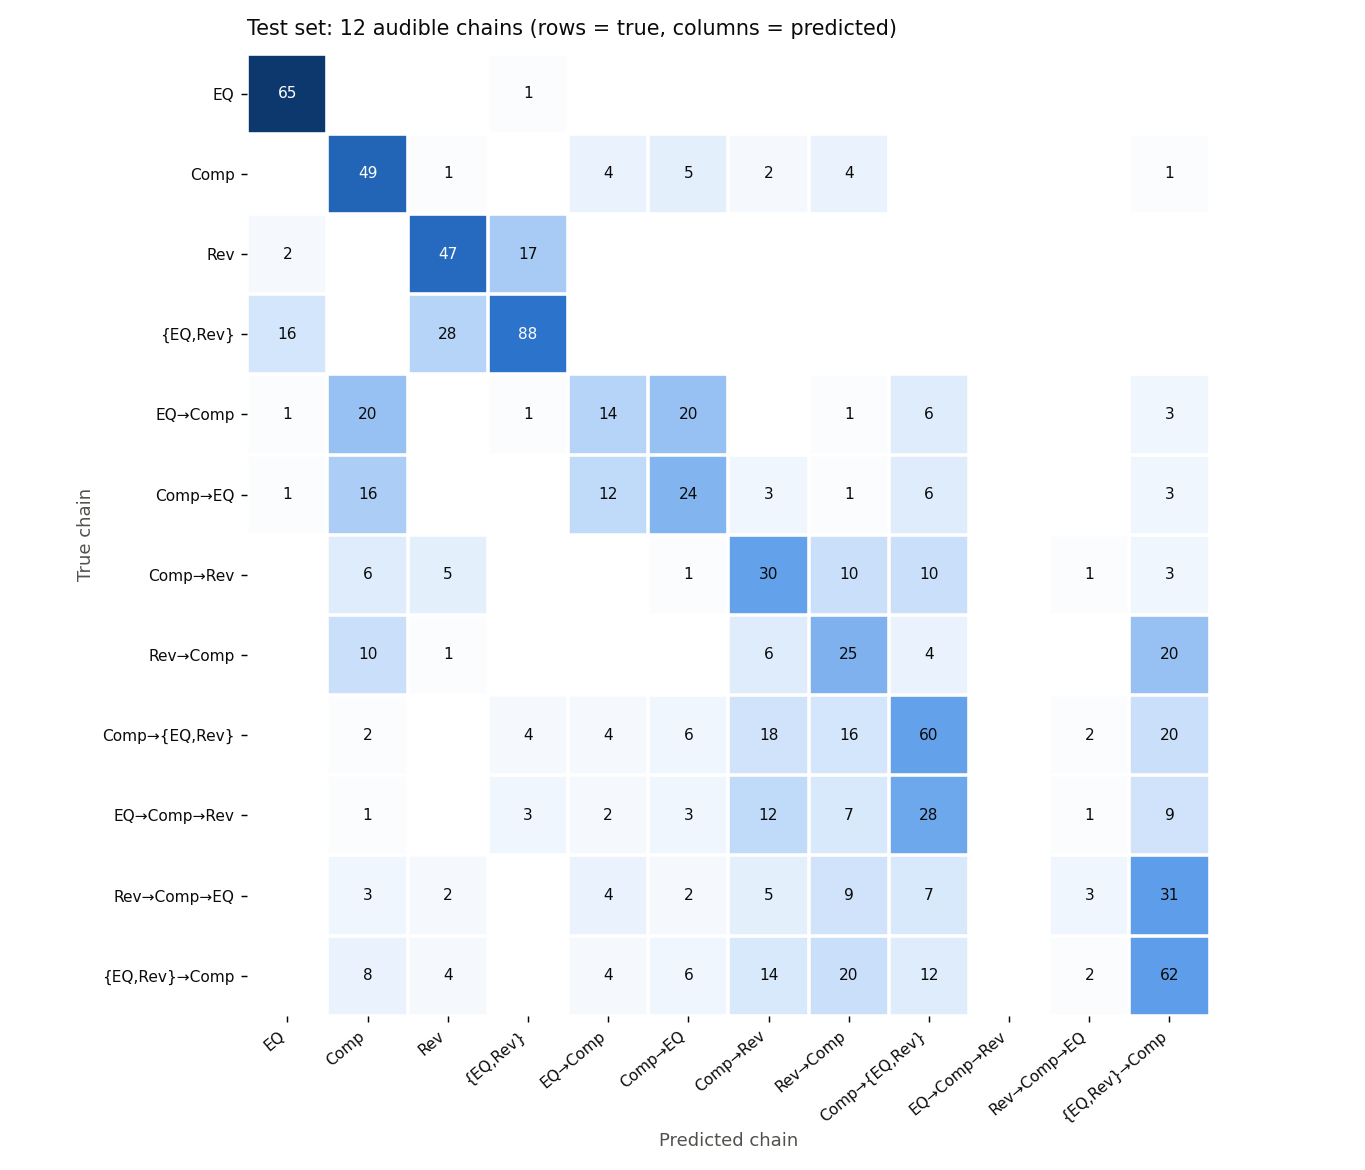

,per-chain accuracy
EQ,0.985
Compressor,0.742
Reverb,0.712
EQ + Reverb (order not audible),0.667
EQ → Compressor,0.212
Compressor → EQ,0.364
Compressor → Reverb,0.455
Reverb → Compressor,0.379
"Compressor → {EQ, Reverb}",0.455
EQ → Compressor → Reverb,0.000


audibility analysed in 4s (1056 order questions)


mean  size
question        bin                                           
eq_before_comp  < −40 dB\n(practically identical)  0.521    48
                > −20 dB\n(clear)                  0.560   200
                −40 … −20 dB\n(subtle)             0.561   280
rev_before_comp > −20 dB\n(clear)                  0.735   528

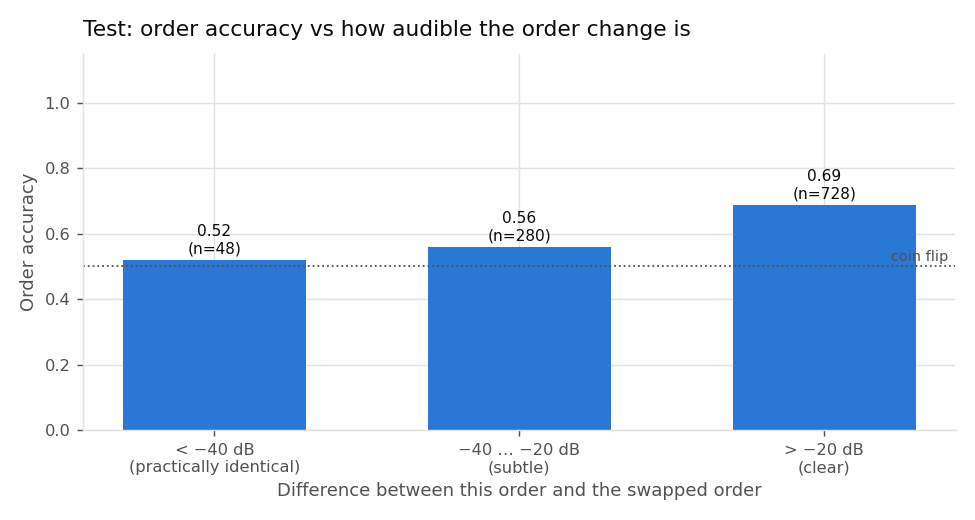

EQ↔Reverb swaps on test: 95th percentile difference -88.6 dB


In [45]:
cm_path = plot_confusion_matrix(TEST_METRICS["chain12_confusion_matrix"], os.path.join(CFG["RESULTS_DIR"], "plots", "test_confusion_matrix_chain12.png"))
display(Image(cm_path))
display(pd.Series(TEST_METRICS["chain12_per_class_accuracy"], name="per-chain accuracy").to_frame().round(3))

t0 = time.time()
test_meta = raw["test"].select_columns(need).cast_column(CFG["WET_AUDIO_COLUMN"], Audio(decode=False))
TEST_ANALYSIS = analyse_split(test_meta, pre, max_groups=CFG["ANALYSIS_MAX_GROUPS"])
ta = pd.DataFrame(TEST_ANALYSIS["audibility"])
pos_of = {int(i): k for k, i in enumerate(idx)}
qj = {q: j for j, q in enumerate(ORDER_KEYS)}
ta["pred"] = [int(op[pos_of[i], qj[q]] >= 0.5) for i, q in zip(ta["index"], ta["question"])]
ta["true"] = [int(test_ds.order[i, qj[q]]) for i, q in zip(ta["index"], ta["question"])]
ta["correct"] = ta["pred"] == ta["true"]
ta["bin"] = ta["diff_db"].map(audibility_bin)
order_bins = [b[2] for b in AUDIBILITY_BINS]
aud_tbl = (ta.groupby("bin")["correct"].agg(["mean", "size"]).reindex(order_bins).dropna()
           .rename(columns={"mean": "accuracy", "size": "n"}).reset_index())
ta.to_csv(os.path.join(CFG["RESULTS_DIR"], "test_order_audibility.csv"), index=False)
print(f"audibility analysed in {time.time() - t0:.0f}s ({len(ta)} order questions)")
display(ta.groupby(["question", "bin"])["correct"].agg(["mean", "size"]).round(3))
aud_path = plot_audibility(aud_tbl.astype({"n": int}), os.path.join(CFG["RESULTS_DIR"], "plots", "test_order_accuracy_vs_audibility.png"))
display(Image(aud_path))
tc = pd.DataFrame(TEST_ANALYSIS["commute"])
print("EQ↔Reverb swaps on test: 95th percentile difference", f"{tc['diff_db'].quantile(0.95):.1f} dB" if len(tc) else "n/a")
AUDIBILITY_MD = ("**Order accuracy vs audibility (test)**\n\n| audibility | accuracy | n |\n|---|---|---|\n" +
                 "\n".join(f"| {b.replace(chr(10), ' ')} | {a:.4f} | {int(n)} |" for b, a, n in aud_tbl[["bin", "accuracy", "n"]].values))

## 27. Training Curves

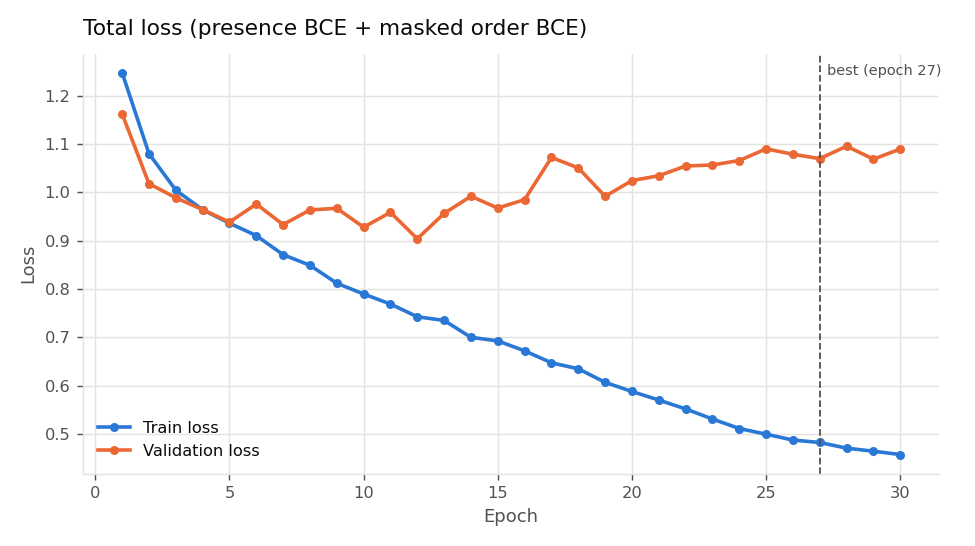

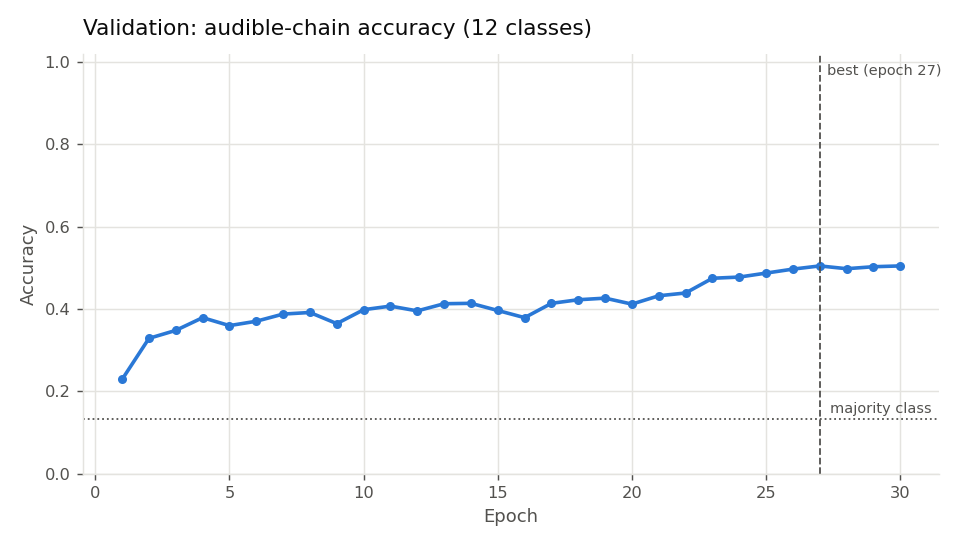

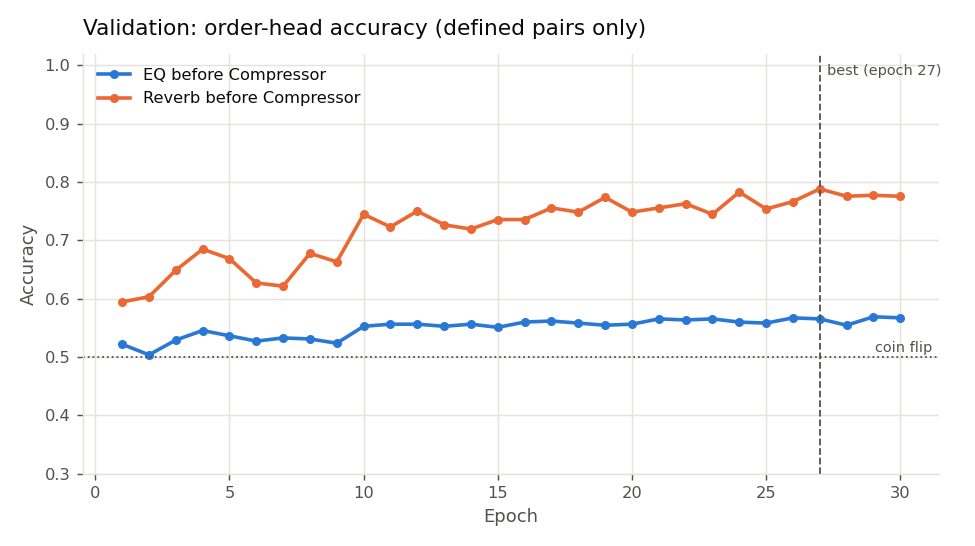

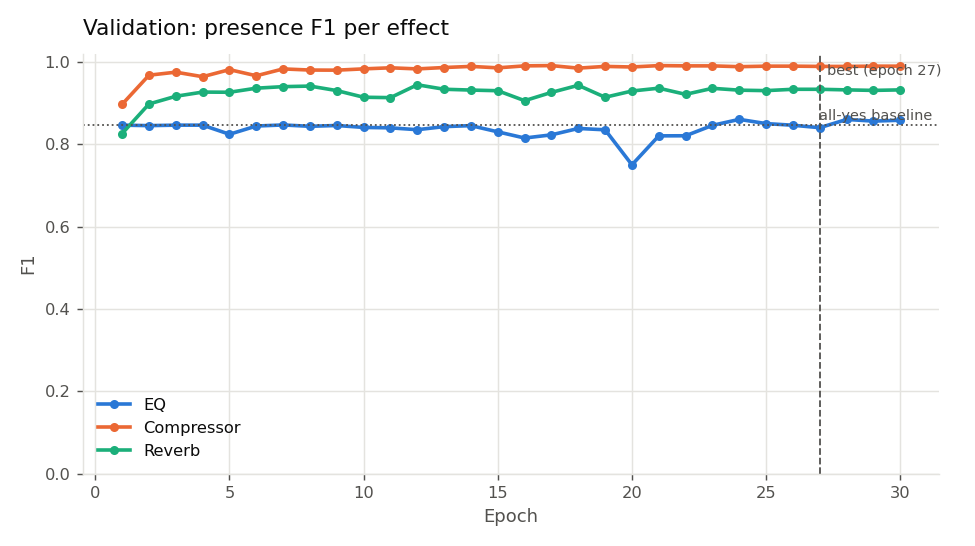

In [46]:
for p in plot_training_curves(HISTORY, os.path.join(CFG["RESULTS_DIR"], "plots"), VAL_BASELINES):
    display(Image(p))

## 28. Final Results + W&B test summary
Test metrics, the confusion matrix and the audibility plot are added to the **same W&B run** used for training.

In [47]:
FINAL = {"experiment": "effect presence + order, two-head Log-Mel Transformer",
         "best_epoch": BEST_STATE["best_epoch"], "epochs_completed": int(hist_df.epoch.max()),
         "validation_at_best": {k: float(best_row[k]) for k in ("validation_chain12_accuracy", "validation_order_accuracy",
                                                               "validation_presence_macro_f1")},
         "test": {k: TEST_METRICS[k] for k in ("chain12_accuracy", "chain15_accuracy", "order/accuracy", "eq_before_comp/accuracy",
                                              "rev_before_comp/accuracy", "chain_set_accuracy", "presence/macro_f1",
                                              "presence/exact_match")},
         "test_baselines": TEST_BASE, "trainable_parameters": N_PARAMS, "world_size": LATEST_STATE.get("world_size"),
         "dataset": CFG["HF_DATASET_ID"], "dataset_revision": CFG["HF_DATASET_REVISION"], "model_repo": CFG["HF_MODEL_ID"]}
atomic_write_json(os.path.join(CFG["RESULTS_DIR"], "final_results.json"), FINAL)
display(pd.Series(FINAL["test"], name="test").to_frame().round(4))

run_id = LATEST_STATE.get("wandb_run_id") or BEST_STATE.get("wandb_run_id")
if WANDB_OK and run_id:
    try:
        import wandb
        run = wandb.init(project=CFG["WANDB_PROJECT"], entity=CFG["WANDB_ENTITY"], id=run_id, resume="allow",
                         dir=WORK_DIR, settings=wandb.Settings(console="off"))
        run.summary.update({f"test/{k}": v for k, v in FINAL["test"].items()} |
                           {f"test_baseline/{k}": v for k, v in TEST_BASE.items()} | {"best_epoch": BEST_STATE["best_epoch"]})
        run.log({"test/confusion_matrix_chain12": wandb.Image(cm_path),
                 "test/order_accuracy_vs_audibility": wandb.Image(aud_path),
                 "test/predictions": wandb.Table(dataframe=pred_df.round(4))})
        print("W&B test summary logged:", run.url)
        run.finish()
    except Exception as e:
        print("W&B test logging skipped:", type(e).__name__, e)
else:
    print("W&B test logging skipped (W&B off or no run id).")

,test
chain12_accuracy,0.4717
chain15_accuracy,0.3657
order/accuracy,0.6458
eq_before_comp/accuracy,0.5568
rev_before_comp/accuracy,0.7348
chain_set_accuracy,0.6333
presence/macro_f1,0.9141
presence/exact_match,0.6677


W&B test logging skipped (W&B off or no run id).


## 29. Save / Push Final Model
`final/` inference bundle + model card + results + TensorBoard + `fxp2/` code + `train.py` in one commit.

In [48]:
FINAL_DIR = os.path.join(WORK_DIR, "final")
shutil.rmtree(FINAL_DIR, ignore_errors=True); os.makedirs(FINAL_DIR)
torch.save(best_model.state_dict(), os.path.join(FINAL_DIR, "model.pt"))
for fn in ("config.json", "training_state.json"):
    shutil.copy2(os.path.join(BEST_DIR, fn), os.path.join(FINAL_DIR, fn))
atomic_write_json(os.path.join(FINAL_DIR, "label_map.json"), BEST_CONFIG["label_mapping"])
atomic_write_json(os.path.join(FINAL_DIR, "test_metrics.json"), TEST_METRICS)
card = build_model_card(eval_cfg, HISTORY, BEST_STATE, TEST_METRICS, TEST_BASE, SHAPES, N_PARAMS, AUDIBILITY_MD)
README_PATH = os.path.join(WORK_DIR, "README.md"); open(README_PATH, "w").write(card)
if hub.enabled:
    ok = hub.push(CFG["CHECKPOINT_DIR"], [], include_best=True, include_pointer=False,
                  extra_dirs={"final": FINAL_DIR, "results": CFG["RESULTS_DIR"], "fxp2": PKG_DIR,
                              os.path.relpath(CFG["TENSORBOARD_DIR"], WORK_DIR): CFG["TENSORBOARD_DIR"]},
                  extra_files={"README.md": README_PATH, "train.py": os.path.join(WORK_DIR, "train.py"),
                               "experiment_config.json": CONFIG_PATH},
                  commit_message=f"final model (best epoch {BEST_STATE['best_epoch']}) + test results")
    print("Pushed final model:", ok, f"-> https://huggingface.co/{CFG['HF_MODEL_ID']}")
else:
    print("Hub disabled — final model saved locally in", FINAL_DIR)

[12:21:35] HF push OK -> APINAJA/inverse-fx-order-logmel-transformer (43 files, 1.9s): - + best
Pushed final model: True -> https://huggingface.co/APINAJA/inverse-fx-order-logmel-transformer


## 30. Final Experiment Summary

In [49]:
t, bb = TEST_METRICS, TEST_BASE
print(f"""
============ EFFECT PRESENCE + ORDER · TWO-HEAD LOG-MEL TRANSFORMER ============
Data       : {CFG['HF_DATASET_ID']} @ {CFG['HF_DATASET_REVISION'][:8]} (train {len(train_ds)} / val {len(val_ds)} / test {len(test_ds)})
Model      : fusion {CFG['FUSION']} -> {SHAPES['fused']} | {CFG['NUM_LAYERS']}x Transformer d={CFG['D_MODEL']} | {N_PARAMS:,} params
Heads      : presence [EQ, Comp, Rev] + order [EQ<Comp, Rev<Comp] | joint decoding over 12 audible chains
Training   : {int(hist_df.epoch.max())} epochs on {LATEST_STATE.get('world_size')} GPU(s), best epoch {BEST_STATE['best_epoch']} (val 12-chain {best_row['validation_chain12_accuracy']:.4f})
TEST       : 12-chain {t['chain12_accuracy']:.4f} (majority {bb['chain12_accuracy_majority_class']:.3f}) | 15-chain {t['chain15_accuracy']:.4f} (ceiling 0.800)
             order {t['order/accuracy']:.4f} (EQ<C {t['eq_before_comp/accuracy']:.4f}, R<C {t['rev_before_comp/accuracy']:.4f}; coin flip 0.5)
             presence macro F1 {t['presence/macro_f1']:.4f} (all-yes {bb['presence_macro_f1_all_yes']:.3f}) | EQ F1 {t['EQ/f1']:.4f}
EQ↔Reverb  : {'commute (merge justified)' if COMMUTE_OK else 'DO NOT commute — check Section 12'}
Hub        : https://huggingface.co/{CFG['HF_MODEL_ID']}
=================================================================================
""")


============ EFFECT PRESENCE + ORDER · TWO-HEAD LOG-MEL TRANSFORMER ============
Data       : APINAJA/inverse-fx-phase1-effect-order @ a5d0eeff (train 4695 / val 1035 / test 990)
Model      : fusion concat_diff -> (16, 862, 384) | 4x Transformer d=256 | 2,274,693 params
Heads      : presence [EQ, Comp, Rev] + order [EQ<Comp, Rev<Comp] | joint decoding over 12 audible chains
Training   : 30 epochs on 2 GPU(s), best epoch 27 (val 12-chain 0.5043)
TEST       : 12-chain 0.4717 (majority 0.133) | 15-chain 0.3657 (ceiling 0.800)
             order 0.6458 (EQ<C 0.5568, R<C 0.7348; coin flip 0.5)
             presence macro F1 0.9141 (all-yes 0.846) | EQ F1 0.8358
EQ↔Reverb  : commute (merge justified)
Hub        : https://huggingface.co/APINAJA/inverse-fx-order-logmel-transformer

